# 제조AI실제 13주차 · TSB-AD 심화: SKAB 이상감지 시스템 설계와 검증

## 1) 개요

- 펌프·수순환 설비의 센서 자료로 정상 운전과 이상 운전을 구분하는 시계열 이상감지 시스템 설계 실습임
- 예측 기반 LSTMAD, 복원 기반 USAD, 대조 기반 PaAno를 사용하여 세 방법의 점수와 경보 특성을 비교함
- 입력의 윈도 길이·센서 구성과 경보의 임계값·평활화·연속 조건을 바꾸어 성능에 미치는 영향을 확인함
- 두 개발 실험에서 오경보 요구를 만족하는 구성을 선정한 뒤, 별도의 세 실험에서 탐지 성능과 조건별 차이를 확인함
- 마지막에는 점수 히스토그램과 경보 위치를 분석하여, 모델의 구분력 문제와 경보 기준의 문제를 구별하는 과정임

## 2) 문제정의

- 설비가 정상으로 운전한 초기 자료를 학습하고, 이후 운전 중 나타나는 이상 구간을 찾아내는 문제임
- 이상을 놓치는 경우와 정상 운전에서 불필요한 경보가 발생하는 경우를 함께 고려함
- 센서값의 크기뿐 아니라 여러 센서의 관계와 시간에 따른 변화를 이용하여 경보 기준을 구성함

| 요구사항 | 이번 실습의 정의 |
|---|---|
| 탐지 대상 | `anomaly=0`은 정상, `anomaly=1`은 이상이며 이상 구간에서 경보가 발생하는지 평가함 |
| 오경보 요구 | 두 개발 파일 각각에서 정상 관측 중 잘못 경보한 비율인 FPR이 10% 이하인 구성 |
| 구성 선정 | 오경보 요구를 만족한 후보 중 두 개발 파일의 평균 F1이 가장 높은 구성 |
| 최종 확인 | 선정에 사용하지 않은 세 시험 파일에 같은 설계 절차를 적용하여 성능 확인 |

- F1은 이상을 얼마나 정확하게, 빠짐없이 경보했는지를 함께 반영하는 지표임. 구체적인 지표 계산은 6장에서 확인
- FPR 10%는 이번 실습에서 정한 운영 요구 수준임

## 3) 데이터정의

- [SKAB 공식 데이터 설명](https://github.com/waico/SKAB/blob/b2c0d46c2971dcbfe71e26087b6d231998bb91c2/README.md)에 따르면 수순환 시험 설비의 8개 센서와 이상·변화점 정답을 제공함
- `valve1`은 펌프 입구 밸브를 닫는 실험, `valve2`는 출구 밸브를 닫는 실험, `other`는 누수·유체 추가 등 다른 운전 변화의 실험임
- 이번 실습은 이상 여부를 나타내는 `anomaly`를 평가 정답으로 사용함

| 센서 | 의미·단위 | 센서 | 의미·단위 |
|---|---|---|---|
| Accelerometer1RMS / 2RMS | 진동 가속도, g | Current | 모터 전류, A |
| Pressure | 펌프 후단 압력, bar | Voltage | 모터 전압, V |
| Temperature | 모터 온도, °C | Thermocouple | 유체 온도, °C |
| RateRMS | 순환 유량, L/min | anomaly | 정상 0·이상 1 |

- 원본의 `Volume Flow RateRMS` 열은 코드에서 `RateRMS`로 이름을 통일함

| 역할 | 사용 파일 | 사용 목적 |
|---|---|---|
| 개발 | `valve1/1.csv`, `valve2/1.csv` | 입력·모델·경보 규칙을 비교하고 구성 선정 |
| 최종 시험 | `valve1/2.csv`, `valve2/2.csv`, `other/3.csv` | 선정한 구성의 새로운 실험 조건 성능 확인 |

- 각 파일은 초기 400개 관측이 정상인 실험을 사용함. 이 정상 준비 구간을 학습·검증·보정에 나누어 사용하는 방법은 4장에서 설명함

**실행 준비**

- Python 3.12 커널과 아래 패키지 환경을 사용함. 환경이 없다면 새 셀에서 다음 명령을 한 번 실행한 뒤 커널을 재시작함

```python
%pip install torch==2.10.0 --index-url https://download.pytorch.org/whl/cu128
%pip install numpy==1.26.4 pandas==2.2.3 matplotlib==3.9.4 scikit-learn==1.6.1 requests==2.32.3 torchinfo==1.8.0 tqdm==4.67.1
```

- 처음 실행할 때 데이터와 모델 소스를 내려받을 인터넷 연결이 필요함
- NVIDIA GPU(CUDA)에서 학습함. RTX 50 시리즈 등 Blackwell GPU는 CUDA 12.8 빌드(cu128)의 PyTorch가 필요함
- GPU 설정은 `torch`를 처음 불러오기 전에 적용되므로, 설정을 바꾸면 **커널을 재시작**한 뒤 Step 1부터 실행함

### Step 1: 실험 조건과 파일 역할 설정

In [1]:
import os

# GPU 설정: torch를 처음 import하기 전에 지정해야 적용됨 (변경 시 커널 재시작)
GPU_ID = "0"                                   # nvidia-smi에 표시되는 GPU 번호
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"  # nvidia-smi와 같은 번호 순서 사용
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID     # 모든 모델이 같은 GPU 하나만 사용
#os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # cuBLAS 결정적 연산에 필요

# CPU 스레드 제한: numpy/torch를 import하기 전에 지정해야 적용됨
# (기본값은 모든 코어를 사용해 작은 GPU 배치에서도 CPU 100%가 발생함)
CPU_THREADS = "2"
for _var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS",
             "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ[_var] = CPU_THREADS

from pathlib import Path
import hashlib
import json
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

LAB_DIR = Path.cwd() / "lab13" if (Path.cwd() / "lab13").is_dir() else Path.cwd()
DATA_DIR = LAB_DIR / "data/SKAB"
OUTPUT_DIR = LAB_DIR / "results/03_tsb_ad_advanced"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SKAB_SHA = "b2c0d46c2971dcbfe71e26087b6d231998bb91c2"
TSB_SHA = "303dffbfc11612995b17b06633f8c9d0ea0e38e5"
DEV_FILES = {"dev_valve1": "valve1/1.csv", "dev_valve2": "valve2/1.csv"}
TEST_FILES = {"test_valve1": "valve1/2.csv", "test_valve2": "valve2/2.csv", "test_other": "other/3.csv"}
TRAIN_END, VALID_END, CALIB_END = 240, 320, 400
MAX_WINDOW, GAP_SECONDS = 64, 5
EDGE_LEFT, EDGE_RIGHT = MAX_WINDOW, MAX_WINDOW // 2
FPR_LIMIT, DEV_SEED, TEST_SEEDS = 0.10, 42, [42, 52, 62]
FEATURES = ["Accelerometer1RMS", "Accelerometer2RMS", "Current", "Pressure",
            "Temperature", "Thermocouple", "Voltage", "RateRMS"]
FEATURE_SETS = {"all8": FEATURES, "process4": ["Accelerometer1RMS", "Current", "Pressure", "RateRMS"]}
print("Development:", DEV_FILES, "| Final test (not loaded yet):", TEST_FILES)

Development: {'dev_valve1': 'valve1/1.csv', 'dev_valve2': 'valve2/1.csv'} | Final test (not loaded yet): {'test_valve1': 'valve1/2.csv', 'test_valve2': 'valve2/2.csv', 'test_other': 'other/3.csv'}


- `DEV_FILES`는 구성을 비교하는 개발 파일, `TEST_FILES`는 선정 후 확인하는 시험 파일 목록임
- 학습·검증·보정 구간의 끝 위치와 비교할 센서 목록을 설정함
- `FPR_LIMIT`는 오경보 요구 수준, 시드는 같은 조건의 실행을 반복하기 위한 값임
- 결과를 저장할 폴더를 준비하고, 이후 셀에서 이 설정을 공통으로 사용함

### Step 2: 개발 데이터 다운로드와 품질 검사

In [2]:
def load_skab(relative):
    path = DATA_DIR / relative
    if not path.is_file():
        url = f"https://raw.githubusercontent.com/waico/SKAB/{SKAB_SHA}/data/{relative}"
        response = requests.get(url, timeout=(15, 90))
        response.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(response.content)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    sidecar = path.with_suffix(path.suffix + ".sha256")
    if sidecar.is_file():
        assert sidecar.read_text().strip().split()[0] == digest, "CSV가 다운로드 기록과 다릅니다."
    else:
        sidecar.write_text(digest, encoding="utf-8")
    frame = pd.read_csv(path, sep=";", parse_dates=["datetime"])
    frame = frame.rename(columns={"Volume Flow RateRMS": "RateRMS"})
    assert set(FEATURES + ["datetime", "anomaly", "changepoint"]).issubset(frame.columns)
    assert frame.datetime.notna().all() and frame.datetime.is_unique and frame.datetime.is_monotonic_increasing
    assert np.isfinite(frame[FEATURES].to_numpy(dtype=float)).all()
    assert frame.anomaly.isin([0, 1]).all() and len(frame) > CALIB_END
    assert frame.anomaly.iloc[:CALIB_END].eq(0).all(), "처음 400개가 정상인 실험만 이 프로토콜에 사용합니다."
    frame.attrs.update(source_commit=SKAB_SHA, sha256=digest, relative_path=relative)
    return frame

development = {name: load_skab(path) for name, path in DEV_FILES.items()}
summary_rows = []
for name, frame in development.items():
    delta = frame.datetime.diff().dt.total_seconds()
    summary_rows.append({"file": name, "observations": len(frame), "anomalies": int(frame.anomaly.sum()),
                         "missing_sensor_values": int(frame[FEATURES].isna().sum().sum()),
                         "median_interval_sec": delta.median(), "max_gap_sec": delta.max(),
                         "gaps_over_5sec": int(delta.gt(GAP_SECONDS).sum())})
display(pd.DataFrame(summary_rows))
display(development["dev_valve1"].head())

,file,observations,anomalies,missing_sensor_values,median_interval_sec,max_gap_sec,gaps_over_5sec
0,dev_valve1,1145,402,0,1.0,2.0,0
1,dev_valve2,1063,333,0,1.0,64.0,1


,datetime,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,RateRMS,anomaly,changepoint
0,2020-03-09 10:34:33,0.027080,0.039615,0.871339,0.054711,75.4955,25.8338,244.091,32.0000,0.0,0.0
1,2020-03-09 10:34:34,0.026995,0.038759,1.301280,0.054711,75.5445,25.8408,224.170,32.0000,0.0,0.0
2,2020-03-09 10:34:35,0.026807,0.039521,1.284500,0.382638,75.6607,25.8227,234.157,32.9986,0.0,0.0
3,2020-03-09 10:34:36,0.026817,0.038630,1.364950,0.054711,75.5750,25.8262,229.902,32.9986,0.0,0.0
4,2020-03-09 10:34:37,0.026393,0.038770,0.791839,0.054711,75.4351,25.8382,251.697,32.0015,0.0,0.0


- 개발 CSV를 내려받고 `datetime`은 시각, `anomaly`는 정답, 8개 센서는 모델 입력으로 구분함
- 센서의 결측·무한값, 시각의 중복·역순, 초기 400개의 정상 여부를 검사함
- 요약표에서 파일별 관측 수·이상 수·수집 간격을 확인함
- 수집 간격이 일정하지 않은 구간이 있으므로 윈도 길이는 초가 아닌 **관측 수**로 다룸

### Step 3: 센서 파형과 정상 센서 관계 시각화

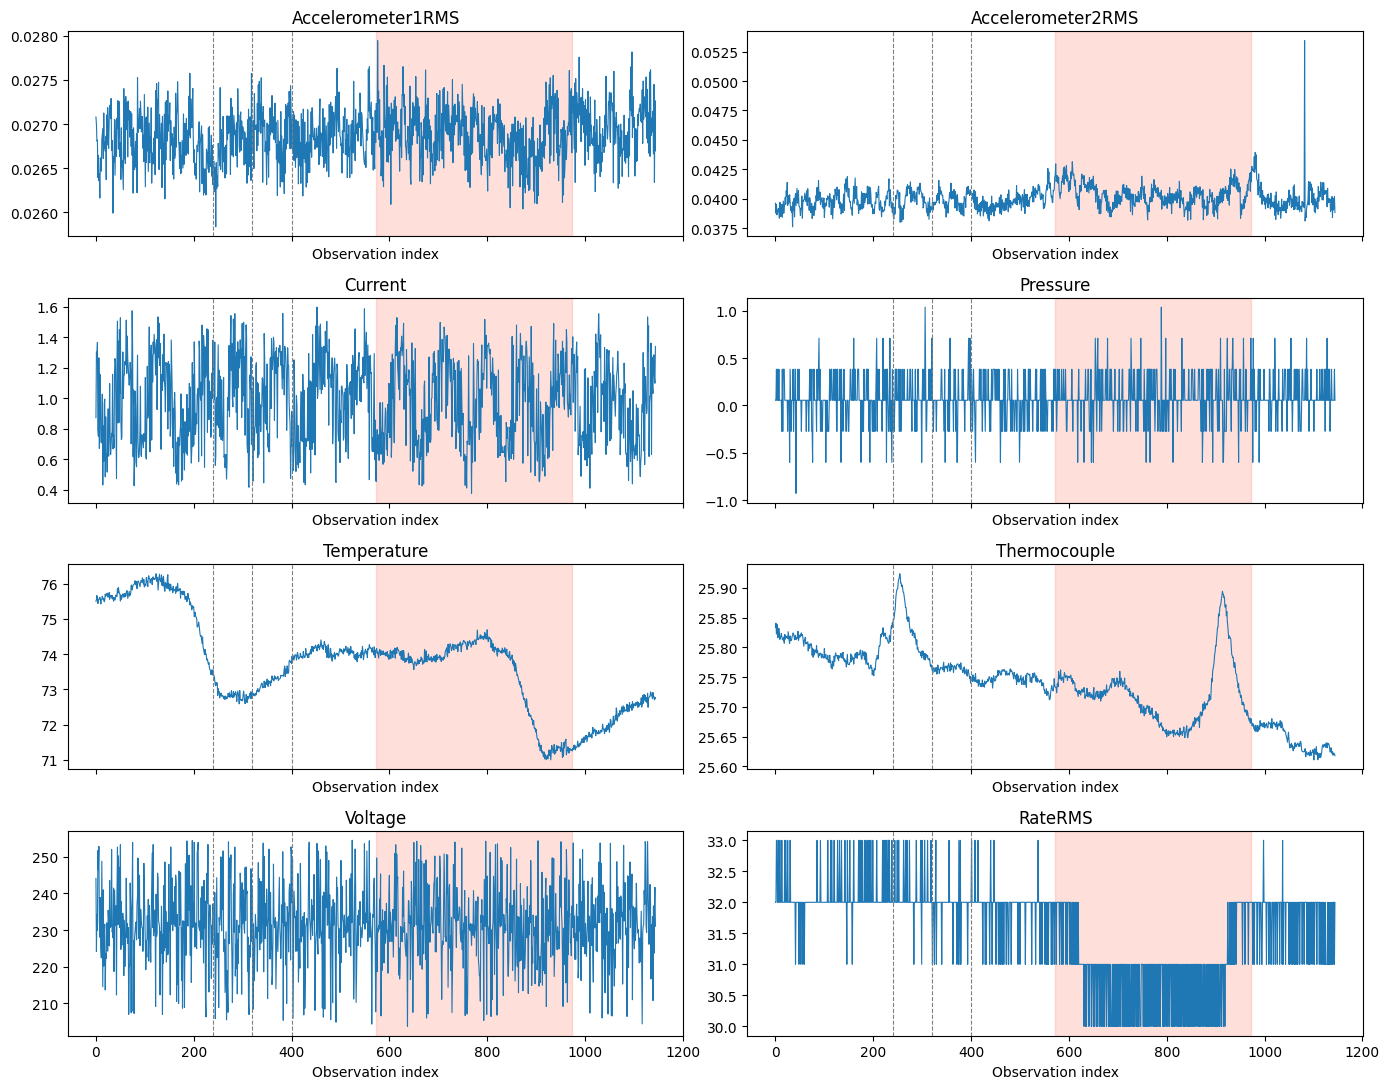

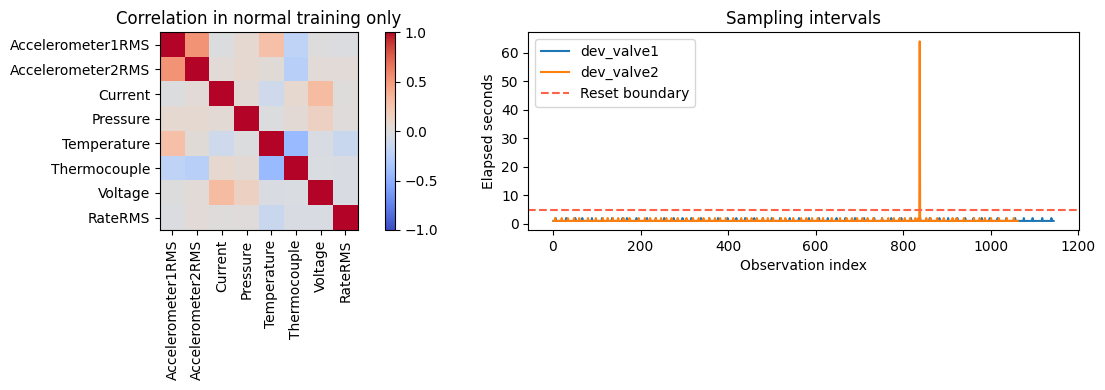

,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,RateRMS
count,240.0000,240.0000,240.0000,240.0000,240.0000,240.0000,240.0000,240.0000
mean,0.0268,0.0397,0.9663,0.0574,75.5539,25.7966,232.1136,32.1375
std,0.0003,0.0008,0.2870,0.2615,0.6564,0.0199,10.7675,0.4209
min,0.0260,0.0376,0.4259,-0.9291,73.4064,25.7525,206.3470,31.0012
25%,0.0266,0.0392,0.7224,0.0547,75.5440,25.7813,226.1370,32.0000
50%,0.0268,0.0397,0.9762,0.0547,75.7149,25.7914,231.4110,32.0000
75%,0.0270,0.0402,1.2140,0.0547,75.9732,25.8152,237.8562,32.0012
max,0.0276,0.0419,1.5726,0.7106,76.2801,25.8413,254.4650,33.0000


In [3]:
frame = development["dev_valve1"]
raw_fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for ax, feature in zip(axes.ravel(), FEATURES):
    ax.plot(frame.index, frame[feature], lw=0.8)
    ax.fill_between(frame.index, 0, 1, where=frame.anomaly.eq(1), transform=ax.get_xaxis_transform(), color="tomato", alpha=0.2)
    for boundary in [TRAIN_END, VALID_END, CALIB_END]:
        ax.axvline(boundary, color="gray", ls="--", lw=0.8)
    ax.set(title=feature, xlabel="Observation index")
raw_fig.tight_layout()
plt.show()
correlation = frame.iloc[:TRAIN_END][FEATURES].corr()
eda_fig, axes = plt.subplots(1, 2, figsize=(13, 4))
image = axes[0].imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
axes[0].set_xticks(range(8), FEATURES, rotation=90)
axes[0].set_yticks(range(8), FEATURES)
axes[0].set_title("Correlation in normal training only")
eda_fig.colorbar(image, ax=axes[0])
for name, frame in development.items():
    axes[1].plot(frame.index, frame.datetime.diff().dt.total_seconds(), label=name)
axes[1].axhline(GAP_SECONDS, color="tomato", ls="--", label="Reset boundary")
axes[1].set(xlabel="Observation index", ylabel="Elapsed seconds", title="Sampling intervals")
axes[1].legend()
eda_fig.tight_layout()
plt.show()
display(development["dev_valve1"].iloc[:TRAIN_END][FEATURES].describe().round(4))

- 8개 센서의 단위·변동 폭과 빨간색 이상 구간의 파형 변화를 확인함
- 센서별 단위 차이를 살펴보고, 다음 장의 표준화가 필요한 이유를 연결함
- 상관계수 그림은 앞 240개의 정상 자료에서 센서들이 함께 변하는 정도를 보여줌
- 수집 간격 그래프의 큰 공백은 이후 윈도를 나누는 위치와 연결하여 확인함

## 4) 입력설계

- 각 파일의 초기 정상 자료 400개를 시간 순서대로 나누어 서로 다른 역할에 사용함
- 정상 학습은 모델이 정상 패턴을 배우는 자료, 정상 검증은 학습 종료를 판단하는 자료, 정상 보정은 경보 임계값을 정하는 자료임
- 이후 평가 구간에는 정상과 이상이 함께 있으며, 개발 파일에서는 구성을 선정하고 시험 파일에서는 선정 결과를 확인함

| 구간 | 관측 수 | 코드의 위치 | 사용 목적 |
|---|---:|---|---|
| 정상 학습 | 240 | `0:240` | 모델의 정상 패턴 학습 |
| 정상 검증 | 80 | `240:320` | LSTMAD·USAD의 학습 종료 판단 |
| 정상 보정 | 80 | `320:400` | 정상 점수로 경보 임계값 계산 |
| 평가 | 나머지 | `400:끝` | 이상 탐지 성능 비교 |

- 표의 끝 위치는 포함하지 않음. 예를 들어 `0:240`은 0번부터 239번까지의 240개 관측임

**윈도와 센서 구성**

| 입력 요소 | 비교 후보 | 확인할 내용 |
|---|---|---|
| 윈도 길이 W | 16 / 32 / 64개 관측 | 짧은 변화와 긴 패턴을 사용하는 차이 |
| 센서 구성 | 전체 8개 / 공정 핵심 4개 | 센서 정보의 기여와 차원 감소의 효과 |

- 핵심 4개는 `Accelerometer1RMS`·`Current`·`Pressure`·`RateRMS`임. 진동·전류·압력·유량으로 펌프 부하와 수순환 변화를 관측하려는 가설임

**센서값의 표준화**

$$
z=\frac{x-\mu}{\sigma}
$$

- x는 센서 관측값, μ는 해당 센서의 평균, σ는 표준편차임. 센서마다 평균 0·표준편차 1에 맞추어 단위와 값의 크기 차이를 줄이는 변환임
- LSTMAD·USAD는 학습·검증·점수화에 전달된 배열에서 각각 평균과 표준편차를 계산함. PaAno는 학습 자료의 평균과 표준편차를 이후 점수 계산에도 사용함
- 표준화와 윈도 생성은 모델이 처리하므로 코드에는 `(관측 수, 센서 수)` 형태의 원본 배열을 전달함

**수집 공백과 양끝 처리**

- 5초를 초과하는 수집 공백에서 자료를 별도 구간으로 나눔. 서로 떨어진 수집 구간을 하나의 윈도로 묶지 않기 위한 처리임
- 윈도를 이용하는 모델은 구간 양끝에서 점수를 계산하는 방식이 다름. 비교할 위치를 맞추기 위해 각 구간의 앞 64개·뒤 32개 점수를 공통으로 제외함
- 보정 점수는 정상 준비 400개를 별도로 점수화한 결과에서 얻음. 보정 구간 80개 중 뒤 32개가 제외되어 **48개 점수**로 임계값을 계산함
- 제외된 위치는 점수 미가용 상태로 두며, 이 위치를 지표에 반영하는 방법은 6장에서 설명함

### Step 4: 입력 후보와 데이터 구간 구성

In [4]:
INPUT_DESIGNS = []
for window, sensors in itertools.product([16, 32, 64], FEATURE_SETS):
    INPUT_DESIGNS.append({"input_id": f"W{window}_{sensors}", "window": window, "sensors": sensors})
INPUT_BY_ID = {design["input_id"]: design for design in INPUT_DESIGNS}
display(pd.DataFrame(INPUT_DESIGNS))
display(pd.DataFrame([
    {"role": "normal training", "start": 0, "end_exclusive": TRAIN_END},
    {"role": "normal validation", "start": TRAIN_END, "end_exclusive": VALID_END},
    {"role": "normal calibration", "start": VALID_END, "end_exclusive": CALIB_END},
    {"role": "design validation or final test", "start": CALIB_END, "end_exclusive": "end"},
]))

,input_id,window,sensors
0,W16_all8,16,all8
1,W16_process4,16,process4
2,W32_all8,32,all8
3,W32_process4,32,process4
4,W64_all8,64,all8
5,W64_process4,64,process4


,role,start,end_exclusive
0,normal training,0,240
1,normal validation,240,320
2,normal calibration,320,400
3,design validation or final test,400,end


- 윈도 3종×센서 2종의 6개 입력안을 생성함
- `INPUT_BY_ID`에서 구성 이름으로 윈도 길이와 센서 목록을 선택할 수 있음
- 구간 표의 시작·끝 위치로 정상 학습·정상 검증·정상 보정·평가 자료를 확인함

### Step 5: 표준화된 입력 샘플과 수집 구간 확인

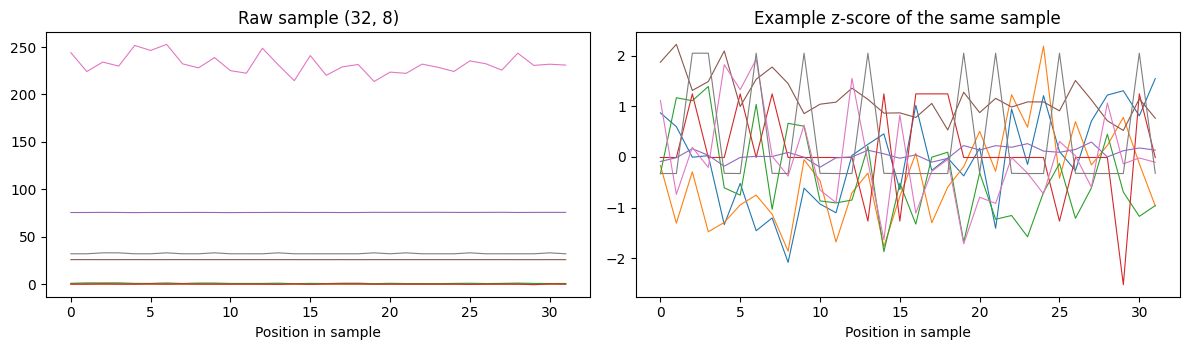

Native API input: (observations, sensors); windows are created internally
Shared excluded edges: 64 32


In [5]:
frame = development["dev_valve1"]
training_values = frame[FEATURES].iloc[:TRAIN_END].to_numpy(dtype=np.float32)
sample = training_values[:32]
sample_mean, sample_std = training_values.mean(axis=0), training_values.std(axis=0)
sample_std = np.where(sample_std == 0, 1, sample_std)
input_fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(sample, lw=0.8)
axes[0].set(title="Raw sample (32, 8)", xlabel="Position in sample")
axes[1].plot((sample-sample_mean)/sample_std, lw=0.8)
axes[1].set(title="Example z-score of the same sample", xlabel="Position in sample")
input_fig.tight_layout()
plt.show()

def segment_bounds(frame):
    gaps = frame.datetime.diff().dt.total_seconds().gt(GAP_SECONDS).to_numpy()
    starts = np.r_[0, np.flatnonzero(gaps)]
    return list(zip(starts, np.r_[starts[1:], len(frame)]))

def common_ranking_mask(frame):
    mask = np.zeros(len(frame), dtype=bool)
    for start, end in segment_bounds(frame.iloc[CALIB_END:]):
        if end-start > EDGE_LEFT+EDGE_RIGHT:
            mask[CALIB_END+start+EDGE_LEFT:CALIB_END+end-EDGE_RIGHT] = True
    return mask

print("Native API input: (observations, sensors); windows are created internally")
print("Shared excluded edges:", EDGE_LEFT, EDGE_RIGHT)

- 왼쪽은 정상 자료의 첫 32개 관측과 8개 센서를 나타내는 `(32, 8)` 샘플임
- 오른쪽은 정상 학습 240개의 평균·표준편차로 같은 샘플을 변환한 예시임. 서로 다른 크기의 센서값을 비슷한 척도에서 살펴볼 수 있음
- 실제 모델에는 원본 배열을 전달하고 각 모델의 표준화를 사용함
- `segment_bounds()`는 큰 공백에서 구간을 나누고, `common_ranking_mask()`는 세 모델을 같은 위치에서 비교할 범위를 표시함

## 5) 방법설계

- 세 방법 모두 정상 자료로 학습하지만, 이상을 점수로 바꾸는 기준이 다름. 점수가 클수록 이상 가능성이 높은 것으로 사용함

| 방법 | TSB-AD 클래스 | 정상 학습과 이상점수의 원리 |
|---|---|---|
| 예측 기반 | `LSTMAD` | 과거 W개 관측으로 다음 1개를 예측하고 실제 관측과의 오차 계산 |
| 복원 기반 | `USAD` | 정상 윈도를 복원하도록 학습하고 두 복원 경로의 오차를 결합 |
| 대조 기반 | `PaAno_PAI` | 정상 패치를 특징 벡터로 표현하고 가까운 정상 참조와의 거리 계산 |

**예측·복원 오차**

$$
s^{\mathrm{LSTM}}=\operatorname{MSE}(x,\hat{x})
$$

$$
s^{\mathrm{USAD}}
=0.1\operatorname{MSE}(W,AE_1(W))
+0.9\operatorname{MSE}(W,AE_2(AE_1(W)))
$$

- x는 실제 다음 관측, x̂는 예측값이며 MSE는 센서별 제곱오차의 평균임
- W는 여러 관측을 묶은 입력 윈도, AE₁·AE₂는 공유 인코더와 각각의 디코더를 이용하는 두 복원 경로임
- USAD는 첫 복원과 교차 복원의 오차를 결합하며, 윈도 전체의 오차를 하나의 점수로 요약함

**정상 특징과의 거리**

- PaAno는 작은 시계열 구간인 패치를 CNN으로 특징 벡터로 바꾸고, 가까운 시점의 정상 패치가 비슷한 특징을 갖도록 대조 학습함
- 학습한 정상 패치의 특징 벡터를 참조 집합에 저장하고, 새 패치와 가장 가까운 정상 참조 3개의 평균 코사인 거리를 점수로 사용함
- 유사한 방향의 특징 벡터는 코사인 거리가 작고, 정상 참조와 다른 특징을 가진 패치는 거리가 커지는 원리임
- 패치가 겹치는 시점은 해당 패치 점수들을 평균하여 관측별 점수로 변환함

**실습 모델과 학습 설정**

- LSTMAD는 은닉차원 20·LSTM 2개 층, USAD는 공유 인코더·디코더 2개, PaAno는 `score_recipe="public_pai"`를 사용함
- LSTMAD·USAD에는 정상 320개를 전달하며, 내부에서 앞 240개는 학습·뒤 80개는 검증으로 사용함. 최대 학습 횟수는 10 epoch임
- PaAno는 정상 240개로 40회 배치 업데이트를 수행하며 특징 차원 16·투영 차원 32를 사용함
- 윈도 길이와 센서 수를 바꾸어도 같은 생성 함수를 통해 각 모델을 준비할 수 있도록 구성함

### Step 6: TSB-AD 실습 버전 준비

In [6]:
import io
import sys
import zipfile
from pathlib import PurePosixPath

TSB_SOURCE_ROOT = LAB_DIR / ".cache" / f"TSB-AD-{TSB_SHA}"
if not (TSB_SOURCE_ROOT / "TSB_AD/models/PaAno_PAI.py").is_file():
    response = requests.get(f"https://api.github.com/repos/thedatumorg/TSB-AD/zipball/{TSB_SHA}", timeout=(15, 90))
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        prefix = archive.namelist()[0].split("/")[0]
        for item in archive.infolist():
            relative = PurePosixPath(item.filename).relative_to(prefix)
            if item.is_dir() or not relative.parts:
                continue
            target = TSB_SOURCE_ROOT.joinpath(*relative.parts)
            assert target.resolve().is_relative_to(TSB_SOURCE_ROOT.resolve())
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(archive.read(item))
sys.path.insert(0, str(TSB_SOURCE_ROOT))
import torch

# 모델 연산은 GPU, CPU 쪽(데이터 준비·후처리) 스레드는 최소화
torch.set_num_threads(int(CPU_THREADS))
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass  # 이미 병렬 작업이 시작된 커널에서는 변경 불가 (커널 재시작 시 적용)

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU를 찾지 못했습니다. CPU로 실행하지 않습니다. "
                       "드라이버와 CUDA 빌드 PyTorch 설치를 확인한 뒤 커널을 재시작하세요.")
DEVICE = torch.device("cuda")
torch.cuda.set_device(0)  # CUDA_VISIBLE_DEVICES로 보이는 첫 GPU
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
print(f"GPU: {torch.cuda.get_device_name(DEVICE)} | CUDA {torch.version.cuda} | torch {torch.__version__}"
      f" | CPU threads {torch.get_num_threads()}")
print("TSB-AD:", TSB_SOURCE_ROOT)

GPU: NVIDIA GeForce RTX 5070 Ti | CUDA 12.8 | torch 2.11.0+cu128 | CPU threads 2
TSB-AD: /home/chohi/PythonProjectLLM/AI_EDU/13w/.cache/TSB-AD-303dffbfc11612995b17b06633f8c9d0ea0e38e5


- TSB-AD 소스를 내려받아 모델을 불러올 경로를 준비함
- 소스 버전을 고정하여 같은 모델 구현으로 실험을 반복할 수 있도록 함
- `DEVICE`에 사용할 GPU를 지정함. LSTMAD·USAD는 공식 코드가 GPU를 자동 선택하고, PaAno에는 `DEVICE`를 직접 전달함
- cuDNN 결정적 모드를 켜서 같은 시드의 GPU 실행 결과가 최대한 같게 나오도록 함. GPU와 CPU의 결과 수치는 소수점 단위로 다를 수 있음

### Step 7: 세 모델의 생성 함수 준비

In [7]:
import contextlib
import io
import random
import time
import numpy as np
import torch
from TSB_AD.models.LSTMAD import LSTMAD
from TSB_AD.models.USAD import USAD
from TSB_AD.models.PaAno_PAI import PaAno_PAI

def prepare_native_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)

def make_lstm(window, n_features, seed):
    prepare_native_seed(seed)
    model = LSTMAD(window_size=window, pred_len=1, feats=n_features,
                  epochs=10, batch_size=64, validation_size=0.25)
    assert next(model.model.parameters()).is_cuda, f"LSTMAD is not on GPU: {model.device}"
    return model

def make_usad(window, n_features, seed):
    prepare_native_seed(seed)
    model = USAD(win_size=window, feats=n_features,
                epochs=10, batch_size=64, validation_size=0.25)
    assert next(model.model.parameters()).is_cuda, f"USAD is not on GPU: {model.device}"
    return model

def make_paano(window, n_features, seed):
    prepare_native_seed(seed)
    patches = TRAIN_END - window + 1
    batch_size = min(32, patches)
    while patches % batch_size == 1:
        batch_size -= 1
    return PaAno_PAI(HP={
        "score_recipe": "public_pai", "patch_size": window, "stride": 1,
        "num_iters": 40, "batch_size": batch_size, "embed_dim": 16, "projection_dim": 32,
        "pretext_step": 1, "top_k": 3, "train_zscore": True, "use_revin": False,
        "device": str(DEVICE), "seed": seed,
    })

- `make_lstm()`·`make_usad()`·`make_paano()`는 윈도 길이·센서 수·시드로 모델을 생성함
- 학습 횟수·배치 크기·검증 비율과 PaAno의 특징 학습 설정을 확인함
- PaAno는 마지막 배치가 1개가 되는 경우를 피하도록 배치 크기를 조정함

### Step 8: 내부 표준화 후 입력값 비교

In [8]:
from TSB_AD.utils.dataset import ForecastDataset, ReconstructDataset

normal = development["dev_valve1"].iloc[:TRAIN_END][FEATURES].to_numpy(dtype=float)
rescaled = normal*7 + 123
forecast_original = ForecastDataset(normal, window_size=32, pred_len=1).samples.numpy()
forecast_rescaled = ForecastDataset(rescaled, window_size=32, pred_len=1).samples.numpy()
reconstruct_original = ReconstructDataset(normal, window_size=32).samples.numpy()
reconstruct_rescaled = ReconstructDataset(rescaled, window_size=32).samples.numpy()
display(pd.DataFrame({"native dataset": ["ForecastDataset", "ReconstructDataset"],
    "maximum absolute difference": [np.max(np.abs(forecast_original-forecast_rescaled)),
                                     np.max(np.abs(reconstruct_original-reconstruct_rescaled))]}))
np.testing.assert_allclose(forecast_original,forecast_rescaled,atol=1e-4)
np.testing.assert_allclose(reconstruct_original,reconstruct_rescaled,atol=1e-4)

,native dataset,maximum absolute difference
0,ForecastDataset,0.0
1,ReconstructDataset,0.0


- 같은 정상 자료에 7을 곱하고 123을 더한 뒤, 표준화된 입력 샘플을 비교함
- 각 센서의 척도와 중심이 달라져도 z-score 결과는 거의 같아짐을 확인함
- 이 특성을 바탕으로 이번 입력 비교는 표준화의 종류보다 윈도 길이와 센서 구성에 집중함

### Step 9: 이름으로 모델을 선택하는 목록 구성

In [9]:
MODEL_REGISTRY = {"LSTMAD": make_lstm, "USAD": make_usad, "PaAno": make_paano}

BASE_INPUT = "W32_all8"
display(pd.DataFrame({"method":list(MODEL_REGISTRY),
    "normal training observations":[240,240,240],
    "internal normal validation observations":[80,80,0],
    "training limit":["10 epochs","10 epochs","40 batch updates"]}))

,method,normal training observations,internal normal validation observations,training limit
0,LSTMAD,240,80,10 epochs
1,USAD,240,80,10 epochs
2,PaAno,240,0,40 batch updates


- `MODEL_REGISTRY`는 모델 이름과 생성 함수를 연결하는 목록임
- 이후 코드에서 이름만 바꾸어 모델을 준비하고 같은 학습·점수 계산 흐름에 연결함
- 표에서 모델별 정상 학습·검증 자료 수와 학습 횟수를 비교함

## 6) 운영규칙설계

- 모델의 출력은 연속적인 이상점수임. 경보를 만들려면 점수가 얼마나 커야 하는지, 얼마나 오래 이어져야 하는지를 정해야 함
- 정상 보정 점수의 상위 분위수를 시작 임계값으로 사용함. 예를 들어 95% 분위수는 보정 점수 중 약 95%가 그 값 이하에 놓이는 기준임

| 운영 요소 | 비교 후보 | 기대 효과와 비용 |
|---|---|---|
| 시작 임계값 | 정상 보정 95% / 97.5% / 99% 분위수 | 높은 기준은 경보를 줄이지만 이상을 놓칠 가능성도 증가 |
| 점수 평활화 | 원점수 / EMA(span=5) | 최근 점수의 흔들림 완화와 변화에 대한 반응의 균형 |
| 점별 경보 | 시작 임계값 초과 시 ON | 한 번의 높은 점수에도 반응 |
| 연속 경보 | 3개 연속 초과한 세 번째 시점부터 ON | 짧은 급등 억제와 경보 시작 지연 |
| 히스테리시스 | 시작 임계값 초과 ON, 정상 보정 90% 분위수 미만 OFF | 경계 근처의 잦은 ON/OFF 완화와 경보 지속 |

- EMA는 현재 점수와 이전 평활값을 가중 평균하는 방법임. 평활화를 사용하는 경우 정상 보정 점수에도 같은 처리를 적용한 뒤 임계값을 계산함
- 3개 분위수×2개 평활화×3개 경보 규칙으로 18개 운영안을 비교함
- 공백과 양끝 제외에 해당하는 NaN 위치에서는 평활화·연속 횟수·경보 상태를 초기화하고 경보를 0으로 둠

**평가 지표**

| 지표 | 확인할 내용 |
|---|---|
| Accuracy | 전체 관측 중 정상·이상 여부를 맞힌 비율 |
| F1 | 경보 중 실제 이상인 비율과 실제 이상 중 경보한 비율을 함께 반영 |
| FPR | 정상 관측 중 잘못 경보한 비율 |
| AUROC·AP | 연속 점수가 정상보다 이상에 높은 값을 주는 정도 |
| EventRecall | 연속된 이상 구간 중 한 번이라도 경보를 낸 구간의 비율 |
| MeanDelayObs / Seconds | 이상 구간 시작부터 첫 경보까지의 관측 수·경과 초 |
| FalseAlarmEvents | 정상 시점에서 새로 시작한 경보 묶음의 수 |

- Accuracy·F1·FPR은 평가 구간 전체 관측으로 계산함. 점수가 없는 이상 관측도 경보 0이므로 미탐으로 반영됨
- AUROC·AP는 모든 후보가 공통으로 점수를 제공하는 위치에서 계산함. 이 위치의 비율인 순위평가 제공률과 점수 제공률을 함께 기록함
- 경보 위치 차이는 탐지된 이상 구간만 평균하므로, 전체 이상 구간의 탐지 여부를 나타내는 EventRecall과 함께 확인함

**경보 위치를 해석할 때의 범위**

- 이번 모델은 점수 계산에 배열 전체의 통계나 관측 이후에 걸친 윈도를 사용할 수 있음. 따라서 자료가 수집된 뒤 점수와 경보를 비교하는 분석임
- 표의 경보 위치 차이는 이러한 점수에서 계산한 값이며, 자료가 도착하는 즉시 경보하는 시스템의 실제 탐지 지연과 구분함

### Step 10: 점수를 경보 상태와 평가 지표로 연결

In [10]:
"""Notebook-ready score smoothing, alarm rules, and unadjusted metrics."""

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def _one_dimensional(values, name, dtype=None):
    result = np.asarray(values, dtype=dtype)
    if result.ndim != 1:
        raise ValueError(f"{name} must be a one-dimensional array")
    return result


def smooth_scores(scores, mode):
    """Use present/past scores only; restart EMA after every NaN run."""
    values = _one_dimensional(scores, "scores", dtype=float)
    if np.isinf(values).any():
        raise ValueError("Infinite model scores must be investigated before smoothing")
    if mode == "raw":
        return values.copy()
    if mode != "ema5":
        raise ValueError("mode must be 'raw' or 'ema5'")
    if not len(values):
        return values.copy()

    # A missing observation begins a new group. The next finite score starts
    # that group's EMA, so state cannot cross a gap or a model warm-up.
    # NumPy loop equivalent to pandas ewm(span=5, adjust=False) per NaN-separated run
    # (pandas groupby+ewm was the CPU bottleneck: hundreds of tiny groups per call).
    alpha = 2.0 / (5 + 1)
    smoothed = np.full(len(values), np.nan, dtype=float)
    state = np.nan
    for i, value in enumerate(values.tolist()):
        if value != value:          # NaN resets the EMA state
            state = np.nan
            continue
        state = value if state != state else (1 - alpha) * state + alpha * value
        smoothed[i] = state
    return smoothed


def alarm_from_scores(scores, high, low, rule):
    """Return process alarms; missing scores reset state and never raise alarms.

    point: score > high.
    consecutive3: alarm starts on the third consecutive score > high; earlier
    observations are not changed. A score <= high immediately ends the alarm.
    hysteresis: score > high turns on; score < low turns off; ties keep state.
    """
    values = _one_dimensional(scores, "scores", dtype=float)
    if np.isinf(values).any():
        raise ValueError("Infinite model scores must be investigated before alarming")
    high = float(high)
    if not np.isfinite(high):
        raise ValueError("high must be finite")
    if rule not in ("point", "consecutive3", "hysteresis"):
        raise ValueError("Unknown alarm rule")
    if rule == "hysteresis":
        low = float(low)
        if not np.isfinite(low) or low > high:
            raise ValueError("Hysteresis requires finite low <= high")

    prediction = np.zeros(len(values), dtype=np.int8)
    if rule == "point":
        prediction[np.isfinite(values) & (values > high)] = 1
        return prediction

    run = 0
    active = False
    # Iterate over Python floats: much faster than per-element NumPy scalar ops.
    for i, value in enumerate(values.tolist()):
        if value != value:  # NaN
            run = 0
            active = False
            continue
        if rule == "consecutive3":
            run = min(run + 1, 3) if value > high else 0
            prediction[i] = int(run >= 3)
        else:
            if value > high:
                active = True
            elif value < low:
                active = False
            prediction[i] = int(active)
    return prediction


def binary_f1_score(y, pred, zero_division=0):
    """Same as sklearn f1_score for binary 0/1 labels, without per-call input validation."""
    y = np.asarray(y) == 1
    pred = np.asarray(pred) == 1
    tp = int(np.sum(y & pred))
    denominator = 2 * tp + int(np.sum(~y & pred)) + int(np.sum(y & ~pred))
    return 2 * tp / denominator if denominator else float(zero_division)


def evaluate(y, pred, score, time=None, ranking_mask=None):
    """Evaluate unchanged point alarms and original anomaly events.

    Point metrics use every input row, including model warm-ups (alarm 0).
    AUROC/AP alone use ranking_mask, or finite scores if the mask is omitted.
    A supplied common mask must contain only finite scores: silently dropping
    additional candidate-specific rows would make rankings incomparable.

    An event is one continuous run of y == 1 in the original timeline.
    An alarm event starts at a 0 -> 1 prediction transition; one beginning on a
    normal row counts as a false-alarm event even if it later overlaps an anomaly.
    Event delay is the first alarm inside an anomaly minus its original onset.
    Missed events remain in EventRecall, but are omitted from mean detected delay.
    """
    target = _one_dimensional(y, "y")
    raw_prediction = _one_dimensional(pred, "pred", dtype=float)
    scores = _one_dimensional(score, "score", dtype=float)
    if not (len(target) == len(raw_prediction) == len(scores)):
        raise ValueError("y, pred, and score must have the same length")
    if not np.isin(target, [0, 1]).all():
        raise ValueError("y must contain only normal 0 and anomaly 1")
    if np.isinf(raw_prediction).any() or np.isinf(scores).any():
        raise ValueError("Infinite predictions or scores are not valid")
    if not np.isin(raw_prediction[np.isfinite(raw_prediction)], [0, 1]).all():
        raise ValueError("pred must contain only 0, 1, or NaN for no alarm")

    target = target.astype(np.int8)
    prediction = np.nan_to_num(raw_prediction, nan=0.0).astype(np.int8)
    finite_scores = np.isfinite(scores)
    if ranking_mask is None:
        rank = finite_scores
    else:
        supplied_mask = _one_dimensional(ranking_mask, "ranking_mask")
        if len(supplied_mask) != len(target) or not np.isin(supplied_mask, [0, 1]).all():
            raise ValueError("ranking_mask must be a same-length boolean mask")
        rank = supplied_mask.astype(bool)
        if np.any(rank & ~finite_scores):
            raise ValueError("Common ranking_mask contains unavailable model scores")

    timestamps = None
    if time is not None:
        raw_time = _one_dimensional(time, "time")
        if len(raw_time) != len(target):
            raise ValueError("time must have one timestamp per original row")
        if np.issubdtype(raw_time.dtype, np.number):
            raise ValueError("time must contain datetimes, not observation indices")
        timestamps = pd.DatetimeIndex(pd.to_datetime(raw_time, errors="raise", utc=True))
        if (timestamps.hasnans or not timestamps.is_monotonic_increasing
                or not timestamps.is_unique):
            raise ValueError("time must be finite, unique, and strictly increasing")

    n = len(target)
    normal = target == 0
    alarm_starts = np.flatnonzero(np.diff(np.r_[0, prediction]) == 1)
    true_edges = np.diff(np.r_[0, target, 0])
    true_starts = np.flatnonzero(true_edges == 1)
    true_ends = np.flatnonzero(true_edges == -1)
    delays = []
    delays_seconds = []
    for start, end in zip(true_starts, true_ends):
        inside_alarm = np.flatnonzero(prediction[start:end] == 1)
        if len(inside_alarm):
            first_alarm = int(start + inside_alarm[0])
            delays.append(first_alarm - int(start))
            if timestamps is not None:
                delays_seconds.append(
                    float((timestamps[first_alarm] - timestamps[start]).total_seconds())
                )

    rank_has_both_classes = len(np.unique(target[rank])) == 2
    # Point metrics from confusion counts (identical to sklearn with zero_division=0,
    # but avoids sklearn's input validation, which dominated CPU time in the search loops).
    actual, alarm = target == 1, prediction == 1
    tp = int(np.sum(actual & alarm))
    fp = int(np.sum(~actual & alarm))
    fn = int(np.sum(actual & ~alarm))
    detected = len(delays)
    true_events = len(true_starts)
    return {
        "Accuracy": float(np.mean(target == prediction)) if n else np.nan,
        "Precision": float(tp / (tp + fp)) if n and tp + fp else (0.0 if n else np.nan),
        "Recall": float(tp / (tp + fn)) if n and tp + fn else (0.0 if n else np.nan),
        "F1": float(2 * tp / (2 * tp + fp + fn)) if n and 2 * tp + fp + fn else (0.0 if n else np.nan),
        "AUROC": float(roc_auc_score(target[rank], scores[rank])) if rank_has_both_classes else np.nan,
        "AP": float(average_precision_score(target[rank], scores[rank])) if rank_has_both_classes else np.nan,
        "FPR": float(prediction[normal].mean()) if normal.any() else np.nan,
        "AlarmRatio": float(prediction.mean()) if n else np.nan,
        "AlarmEvents": int(len(alarm_starts)),
        "FalseAlarmEvents": int(np.sum(target[alarm_starts] == 0)),
        "EventRecall": float(detected / true_events) if true_events else np.nan,
        "MeanDelayObs": float(np.mean(delays)) if detected else np.nan,
        "MeanDelaySeconds": float(np.mean(delays_seconds)) if delays_seconds else np.nan,
        "DetectedEvents": int(detected),
        "TrueEvents": int(true_events),
        "ScoredCoverage": float(finite_scores.mean()) if n else np.nan,
        "RankingCoverage": float(rank.mean()) if n else np.nan,
        "RankedObservations": int(rank.sum()),
        "TotalObservations": int(n),
    }

- `smooth_scores()`는 원점수를 유지하거나 EMA로 평활화하며, NaN 다음에는 새로 시작함
- `alarm_from_scores()`는 점별·3연속·히스테리시스 규칙을 적용하여 0 또는 1의 경보를 생성함
- `evaluate()`는 같은 경보에서 시점별 탐지 성능과 이상 구간별 탐지 여부를 계산함
- 순위 지표에는 공통 유효 위치를 전달하여 같은 관측끼리 점수 구분력을 비교함

### Step 11: 운영 후보의 설정 목록 생성

In [11]:
OPERATIONS = []
for q, smoothing, trigger in itertools.product([0.95, 0.975, 0.99], ["raw", "ema5"], ["point", "consecutive3", "hysteresis"]):
    OPERATIONS.append({"operation_id": f"q{q:g}_{smoothing}_{trigger}", "q": q,
                       "smoothing": smoothing, "trigger": trigger})
OP_BY_ID = {operation["operation_id"]: operation for operation in OPERATIONS}
BASE_OPERATION = "q0.99_raw_point"
display(pd.DataFrame(OPERATIONS))
print("Total candidate configurations:", len(INPUT_DESIGNS) * len(MODEL_REGISTRY) * len(OPERATIONS))

,operation_id,q,smoothing,trigger
0,q0.95_raw_point,0.950,raw,point
1,q0.95_raw_consecutive3,0.950,raw,consecutive3
2,q0.95_raw_hysteresis,0.950,raw,hysteresis
3,q0.95_ema5_point,0.950,ema5,point
4,q0.95_ema5_consecutive3,0.950,ema5,consecutive3
5,q0.95_ema5_hysteresis,0.950,ema5,hysteresis
6,q0.975_raw_point,0.975,raw,point
7,q0.975_raw_consecutive3,0.975,raw,consecutive3
8,q0.975_raw_hysteresis,0.975,raw,hysteresis
9,q0.975_ema5_point,0.975,ema5,point


Total candidate configurations: 324


- `OPERATIONS`에 분위수·평활화·경보 규칙을 조합한 18개 운영안을 저장함
- `OP_BY_ID`에서 이름으로 운영안을 선택할 수 있음
- 기본 운영안은 평활화 없는 99% 분위수의 점별 경보이며, 입력 6개·모델 3개와 조합하여 324개 구성을 비교함

## 7) 시스템설계

- 앞에서 만든 입력안·모델·운영 규칙을 하나의 파이프라인으로 연결함
- 같은 데이터 구간과 평가 함수를 사용하면 구성 요소를 바꾸었을 때의 차이를 비교하기 쉬워짐

```text
정상 준비 400개
  ├─ 학습 240개 → 정상 패턴 학습
  ├─ 검증 80개 → LSTMAD·USAD의 학습 종료 판단
  └─ 정상 준비 점수 계산 → 보정 유효 점수 48개 → 경보 임계값

평가 자료 → 센서 선택·공백별 구간 분리
         → 모델 점수 → 공통 양끝 제외
         → 점수 평활화 → 경보 규칙 → 평가 지표

개발 파일의 구성 비교 → 구성 선정 → 별도 시험 → 히스토그램 분석
```

- 보정 점수는 정상 준비 자료에서 계산하고, 평가 자료는 별도로 점수화함
- 입력 구성과 모델을 바꾸면 학습을 다시 수행하고, 같은 점수에서 운영 규칙만 바꿀 때는 점수를 재사용함
- 경보 상태와 EMA는 평가 구간의 시작 및 NaN 다음에서 새로 시작함

### Step 12: 입력·모델·경보를 연결하는 파이프라인

In [12]:
class ADPipeline:
    """Connect unchanged native detectors to fixed data roles and alarm rules."""

    def __init__(self, input_design, method, seed=42):
        self.input_design, self.method, self.seed = dict(input_design), method, int(seed)
        self.features = list(input_design.get("features", FEATURE_SETS[input_design["sensors"]]))
        self.window = int(input_design["window"])

    def fit(self, normal_prefix):
        assert len(normal_prefix) == CALIB_END and normal_prefix.anomaly.eq(0).all()
        assert len(segment_bounds(normal_prefix)) == 1, "Normal preparation must not cross a collection gap"
        values = normal_prefix[self.features].to_numpy(dtype=np.float32)
        assert np.isfinite(values).all()
        started = time.perf_counter()
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            self.model = MODEL_REGISTRY[self.method](self.window, len(self.features), self.seed)
            if self.method == "PaAno":
                self.model.fit(values[:TRAIN_END])
            else:
                # The native 25% validation split is 240 training + 80 validation.
                self.model.fit(values[:VALID_END])
        self.fit_seconds_ = time.perf_counter() - started
        # Score only known-normal preparation here; test statistics never enter this call.
        self.prefix_scores = self.score_array(values)
        self.validation_score_mean = float(np.nanmean(self.prefix_scores[TRAIN_END:VALID_END]))
        calibration = self.prefix_scores[VALID_END:CALIB_END]
        assert np.isfinite(calibration).sum() == CALIB_END - VALID_END - EDGE_RIGHT
        return self

    def score_array(self, values):
        values = np.asarray(values, dtype=np.float32)
        assert values.ndim == 2 and values.shape[1] == len(self.features)
        assert np.isfinite(values).all()
        score = np.full(len(values), np.nan, dtype=float)
        # This guard also prevents native empty-window errors and PaAno fallback scoring.
        if len(values) <= EDGE_LEFT + EDGE_RIGHT:
            return score
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            native = np.asarray(self.model.decision_function(values), dtype=float).reshape(-1)
        assert len(native) == len(values) and np.isfinite(native).all()
        score[EDGE_LEFT:len(values) - EDGE_RIGHT] = native[EDGE_LEFT:len(values) - EDGE_RIGHT]
        return score

    def raw_scores(self, frame):
        score = np.full(len(frame), np.nan, dtype=float)
        tail = frame.iloc[CALIB_END:]
        values = tail[self.features].to_numpy(dtype=np.float32)
        for start, end in segment_bounds(tail):
            score[CALIB_END + start:CALIB_END + end] = self.score_array(values[start:end])
        return score

    def operate(self, raw_score, operation):
        smoothed = smooth_scores(raw_score, operation["smoothing"])
        reference = smooth_scores(self.prefix_scores, operation["smoothing"])[VALID_END:CALIB_END]
        reference = reference[np.isfinite(reference)]
        assert len(reference) == CALIB_END - VALID_END - EDGE_RIGHT
        high, low = np.quantile(reference, [operation["q"], 0.90])
        alarms = alarm_from_scores(smoothed[CALIB_END:], high, low, operation["trigger"])
        return {"score": smoothed[CALIB_END:], "prediction": alarms,
                "high": float(high), "low": float(low)}

def run_metrics(frame, prediction):
    part = frame.iloc[CALIB_END:]
    return evaluate(part.anomaly.to_numpy(), prediction["prediction"], prediction["score"],
                    time=part.datetime.to_numpy(), ranking_mask=common_ranking_mask(frame)[CALIB_END:])

def fit_and_cache(frame, input_design, method, seed):
    pipeline = ADPipeline(input_design, method, seed).fit(frame.iloc[:CALIB_END])
    return {"pipeline": pipeline, "raw": pipeline.raw_scores(frame)}

- `ADPipeline`은 입력 구성·모델 이름·시드를 받아 학습과 점수 계산을 연결함
- `fit()`에서 정상 자료로 학습하고 정상 보정 점수를 준비함
- `raw_scores()`에서 평가 자료를 공백별로 나누어 모델 점수를 계산함
- `operate()`에서 정상 보정 임계값과 경보 규칙을 적용하고, `run_metrics()`에서 평가 정답과 비교함

### Step 13: 예제 구성의 경보와 보정 자료 분리 확인

In [13]:
import numpy as np
np.Inf = np.inf

example_frame = development["dev_valve1"]
example = fit_and_cache(example_frame, INPUT_BY_ID[BASE_INPUT], "LSTMAD", DEV_SEED)
example_alarm = example["pipeline"].operate(example["raw"], OP_BY_ID[BASE_OPERATION])
display(pd.DataFrame([run_metrics(example_frame, example_alarm)]).round(4))
reference_before = example["pipeline"].prefix_scores.copy()
modified_test = example_frame.copy()
modified_test.loc[modified_test.index[-50:], FEATURES] *= 2
modified_score = example["pipeline"].raw_scores(modified_test)
modified_alarm = example["pipeline"].operate(modified_score, OP_BY_ID[BASE_OPERATION])
np.testing.assert_array_equal(reference_before, example["pipeline"].prefix_scores)
assert modified_alarm["high"] == example_alarm["high"]
assert np.isfinite(reference_before[VALID_END:CALIB_END]).sum() == 48
assert type(example["pipeline"].model) is LSTMAD
assert alarm_from_scores([2,2,2,0],1,0.5,"consecutive3").tolist() == [0,0,1,0]
assert alarm_from_scores([2,0.8,0.3,np.nan,0.8],1,0.5,"hysteresis").tolist() == [1,1,0,0,0]
print("Passed: native class, 48 calibration scores, calibration independent of test values")

,Accuracy,Precision,Recall,F1,AUROC,AP,FPR,AlarmRatio,AlarmEvents,FalseAlarmEvents,EventRecall,MeanDelayObs,MeanDelaySeconds,DetectedEvents,TrueEvents,ScoredCoverage,RankingCoverage,RankedObservations,TotalObservations
0,0.4886,0.7333,0.0821,0.1477,0.5313,0.6612,0.035,0.0604,25,11,1.0,1.0,1.0,1,1,0.8711,0.8711,649,745


Passed: native class, 48 calibration scores, calibration independent of test values


- W32·전체 8개 센서·LSTMAD를 준비하고 기본 운영안의 경보와 평가 지표를 계산함
- 평가 자료 끝부분의 센서값을 바꾼 뒤에도 정상 보정 점수와 임계값이 같은지 확인함
- 정상 보정 자료에서 정한 경보 기준과 이후 평가 자료의 역할이 분리되어 있음을 확인하는 예제임
- 작은 점수 배열로 3연속 경보와 히스테리시스의 ON/OFF 동작도 확인함

## 8) 실험분석

### 8-1) 개발 실험과 선정 기준

- 개발 파일 `valve1/1.csv`와 `valve2/1.csv`에서 입력 6종×모델 3종을 학습하고 운영 규칙 18종을 적용함
- 총 **36회 학습·324개 구성**을 비교하여 두 개발 파일 각각 FPR 10% 이하인 후보 중 평균 F1이 가장 높은 구성을 선정함
- 입력·방법·운영 규칙을 비교한 뒤 별도 시험 파일에서 성능을 확인함
- F1은 실제 경보의 탐지 성능, AUROC는 점수의 정상·이상 구분력, FPR은 정상 관측 중 잘못 경보한 비율임

### Step 14: 개발 후보 학습과 경보 실험 실행

In [14]:
cache = {(BASE_INPUT, "LSTMAD", "dev_valve1"): example}
trial_rows, fit_rows = [], []
search_started = time.perf_counter()
for input_index, design in enumerate(INPUT_DESIGNS, 1):
    for method in MODEL_REGISTRY:
        for file_name, frame in development.items():
            key = (design["input_id"], method, file_name)
            if key not in cache:
                cache[key] = fit_and_cache(frame, design, method, DEV_SEED)
            entry = cache[key]
            native_pipeline = entry["pipeline"]
            fit_rows.append({**design, "method": method, "file": file_name,
                             "fit_seconds": native_pipeline.fit_seconds_,
                             "native_class": type(native_pipeline.model).__module__ + "." + type(native_pipeline.model).__name__,
                             "calibration_points": int(np.isfinite(native_pipeline.prefix_scores[VALID_END:CALIB_END]).sum()),
                             "normal_validation_score": native_pipeline.validation_score_mean})
            for operation in OPERATIONS:
                prediction = entry["pipeline"].operate(entry["raw"], operation)
                trial_rows.append({**design, **operation, "method": method, "file": file_name,
                                   **run_metrics(frame, prediction)})
    print(f"Inputs {input_index:02d}/{len(INPUT_DESIGNS)} completed | {time.perf_counter()-search_started:.1f}s", flush=True)
trials, fit_log = pd.DataFrame(trial_rows), pd.DataFrame(fit_rows)
group_keys = ["input_id", "window", "sensors", "method", "operation_id", "q", "smoothing", "trigger"]
metric_columns = ["Accuracy", "Precision", "Recall", "F1", "AUROC", "AP", "FPR", "AlarmRatio", "AlarmEvents",
                  "FalseAlarmEvents", "EventRecall", "MeanDelayObs", "MeanDelaySeconds", "ScoredCoverage", "RankingCoverage"]
comparison = trials.groupby(group_keys, as_index=False)[metric_columns].mean()
worst = trials.groupby(group_keys, as_index=False).FPR.max().rename(columns={"FPR": "WorstFPR"})
comparison = comparison.merge(worst, on=group_keys)
comparison["feasible"] = comparison.WorstFPR <= FPR_LIMIT
comparison["utility"] = comparison.F1 - 0.5 * comparison.FPR

def select_best(table):
    eligible = table[table.feasible]
    first = ["F1"] if len(eligible) else ["utility", "F1"]
    source = eligible if len(eligible) else table
    return source.sort_values(first + ["FPR", "FalseAlarmEvents", "window", "input_id", "operation_id", "method"],
                              ascending=[False]*len(first) + [True]*6).iloc[0]

best_development = select_best(comparison)
print("Fits:", len(fit_log), "| File-level trials:", len(trials), "| Configurations:", len(comparison),
      "| Feasible:", int(comparison.feasible.sum()))
display(comparison.sort_values(["feasible", "F1"], ascending=False).head(10).round(4))
trials.to_csv(OUTPUT_DIR / "development_trials.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "development_macro.csv", index=False)
fit_log.to_csv(OUTPUT_DIR / "training_log.csv", index=False)

Inputs 01/6 completed | 1.7s
Inputs 02/6 completed | 2.9s
Inputs 03/6 completed | 4.1s
Inputs 04/6 completed | 5.4s
Inputs 05/6 completed | 6.5s
Inputs 06/6 completed | 7.6s
Fits: 36 | File-level trials: 648 | Configurations: 324 | Feasible: 162


,input_id,window,sensors,method,operation_id,q,smoothing,trigger,Accuracy,Precision,...,AlarmEvents,FalseAlarmEvents,EventRecall,MeanDelayObs,MeanDelaySeconds,ScoredCoverage,RankingCoverage,WorstFPR,feasible,utility
310,W64_process4,64,process4,USAD,q0.95_raw_hysteresis,0.950,raw,hysteresis,0.7254,1.0,...,1.5,0.0,1.0,77.0,81.5,0.7908,0.7908,0.0,True,0.5759
307,W64_process4,64,process4,USAD,q0.95_ema5_hysteresis,0.950,ema5,hysteresis,0.7253,1.0,...,1.5,0.0,1.0,78.0,82.5,0.7908,0.7908,0.0,True,0.5746
308,W64_process4,64,process4,USAD,q0.95_ema5_point,0.950,ema5,point,0.7253,1.0,...,1.5,0.0,1.0,78.0,82.5,0.7908,0.7908,0.0,True,0.5746
311,W64_process4,64,process4,USAD,q0.95_raw_point,0.950,raw,point,0.7240,1.0,...,1.5,0.0,1.0,77.0,81.5,0.7908,0.7908,0.0,True,0.5729
316,W64_process4,64,process4,USAD,q0.975_raw_hysteresis,0.975,raw,hysteresis,0.7240,1.0,...,1.5,0.0,1.0,77.5,82.0,0.7908,0.7908,0.0,True,0.5729
322,W64_process4,64,process4,USAD,q0.99_raw_hysteresis,0.990,raw,hysteresis,0.7240,1.0,...,1.5,0.0,1.0,77.5,82.0,0.7908,0.7908,0.0,True,0.5729
313,W64_process4,64,process4,USAD,q0.975_ema5_hysteresis,0.975,ema5,hysteresis,0.7246,1.0,...,1.5,0.0,1.0,78.0,82.5,0.7908,0.7908,0.0,True,0.5723
314,W64_process4,64,process4,USAD,q0.975_ema5_point,0.975,ema5,point,0.7246,1.0,...,1.5,0.0,1.0,78.0,82.5,0.7908,0.7908,0.0,True,0.5723
319,W64_process4,64,process4,USAD,q0.99_ema5_hysteresis,0.990,ema5,hysteresis,0.7239,1.0,...,1.5,0.0,1.0,78.5,83.0,0.7908,0.7908,0.0,True,0.5715
320,W64_process4,64,process4,USAD,q0.99_ema5_point,0.990,ema5,point,0.7239,1.0,...,1.5,0.0,1.0,78.5,83.0,0.7908,0.7908,0.0,True,0.5715


- 같은 입력·모델·파일에서 얻은 점수를 재사용하여 운영 규칙의 효과를 비교함
- `WorstFPR`은 두 개발 파일 중 더 큰 오경보율임. 평균 FPR과 함께 확인하여 파일별 요구 수준을 평가함

### 8-2) 입력설계의 효과

- 운영 규칙을 **99% 분위수·원점수·점별 경보**로 고정하고 윈도 길이와 센서 구성의 효과를 비교함
- 센서 8개에서 윈도를 바꾸는 비교와 W32에서 센서를 바꾸는 비교를 구분함

### Step 15: 다른 조건을 고정한 입력 요소 비교

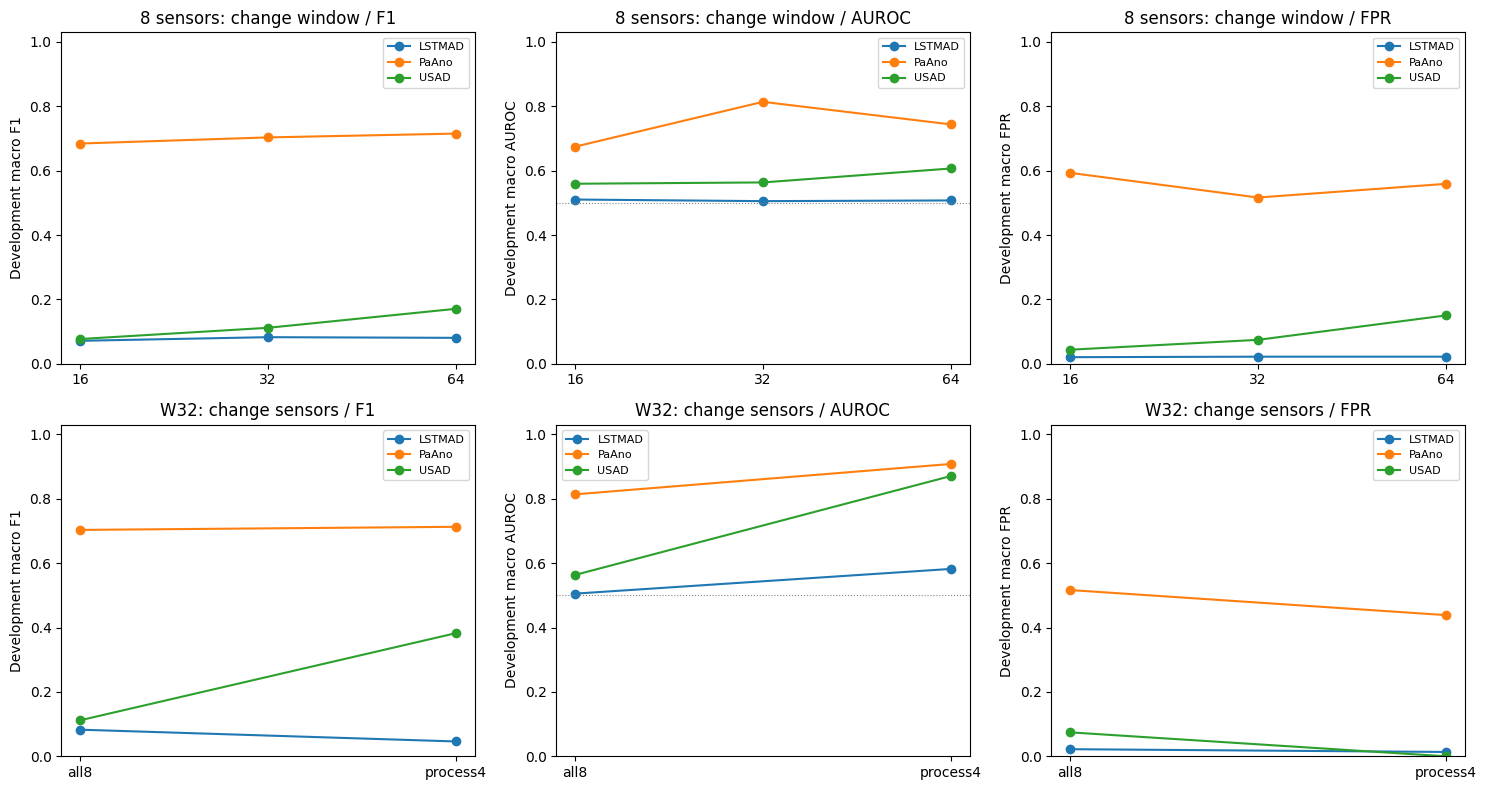

Factor: window


,window,method,F1,FPR,AP,AUROC,ScoredCoverage
17,16,LSTMAD,0.0714,0.0205,0.5859,0.5104,0.7908
35,16,PaAno,0.6844,0.5934,0.7801,0.6747,0.7908
53,16,USAD,0.0769,0.0437,0.6328,0.5595,0.7908
125,32,LSTMAD,0.0827,0.0220,0.5818,0.5054,0.7908
143,32,PaAno,0.7035,0.5166,0.8913,0.8140,0.7908
161,32,USAD,0.1118,0.0743,0.6452,0.5635,0.7908
233,64,LSTMAD,0.0806,0.0220,0.5832,0.5076,0.7908
251,64,PaAno,0.7153,0.5591,0.8377,0.7439,0.7908
269,64,USAD,0.1708,0.1501,0.6820,0.6069,0.7908


Factor: sensors


,sensors,method,F1,FPR,AP,AUROC,ScoredCoverage
125,all8,LSTMAD,0.0827,0.0220,0.5818,0.5054,0.7908
143,all8,PaAno,0.7035,0.5166,0.8913,0.8140,0.7908
161,all8,USAD,0.1118,0.0743,0.6452,0.5635,0.7908
179,process4,LSTMAD,0.0461,0.0134,0.6383,0.5822,0.7908
197,process4,PaAno,0.7131,0.4387,0.9551,0.9084,0.7908
215,process4,USAD,0.3825,0.0000,0.9097,0.8708,0.7908


Window comparison with process4; the same q99/raw/point rule


,method,window,F1,FPR,AUROC
71,LSTMAD,16,0.0461,0.0119,0.5807
179,LSTMAD,32,0.0461,0.0134,0.5822
287,LSTMAD,64,0.0439,0.0119,0.5929
89,PaAno,16,0.7580,0.2248,0.8873
197,PaAno,32,0.7131,0.4387,0.9084
305,PaAno,64,0.7552,0.4828,0.9846
107,USAD,16,0.3437,0.0000,0.8380
215,USAD,32,0.3825,0.0000,0.8708
323,USAD,64,0.5632,0.0000,0.9477


In [15]:
base_rules = comparison[comparison.operation_id.eq(BASE_OPERATION)]
ablation_tables = {"window": base_rules[base_rules.sensors.eq("all8")],
                   "sensors": base_rules[base_rules.window.eq(32)]}
ablation_fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (factor, table) in enumerate(ablation_tables.items()):
    for col, metric in enumerate(["F1", "AUROC", "FPR"]):
        ax = axes[row, col]
        for method, group in table.groupby("method"):
            group = group.sort_values(factor)
            ax.plot(group[factor].astype(str), group[metric], "o-", label=method)
        condition = "8 sensors: change window" if factor == "window" else "W32: change sensors"
        ax.set(title=f"{condition} / {metric}", ylabel=f"Development macro {metric}", ylim=(0, 1.03))
        if metric == "AUROC":
            ax.axhline(0.5, color="gray", ls=":", lw=0.8)
        ax.legend(fontsize=8)
ablation_fig.tight_layout()
plt.show()
for factor, table in ablation_tables.items():
    print("Factor:", factor)
    display(table[[factor, "method", "F1", "FPR", "AP", "AUROC", "ScoredCoverage"]].round(4))
print("Window comparison with process4; the same q99/raw/point rule")
process_window = base_rules[base_rules.sensors.eq("process4")]
display(process_window[["method", "window", "F1", "FPR", "AUROC"]].sort_values(["method", "window"]).round(4))

- 위쪽 그래프는 센서 8개를 고정한 윈도 비교, 아래쪽은 W32를 고정한 센서 비교임. F1·AUROC는 높을수록, FPR은 낮을수록 좋은 방향임
- 센서 8개에서 USAD의 W16→W64 F1은 **0.0769→0.1708**로 높아지지만 FPR도 **4.37%→15.01%**로 높아짐
- 핵심 4개를 사용하면 USAD의 W16→W64 F1은 **0.3437→0.5632**, AUROC는 **0.8380→0.9477**로 높아지고 FPR은 모두 **0%**임
- W32에서 센서 8개→4개로 줄이면 USAD의 F1은 **0.1118→0.3825**, PaAno의 AUROC는 **0.6955→0.9344**로 개선됨
- 같은 변경에서 LSTMAD의 AUROC는 **0.5054→0.5822**로 높아져도 F1은 **0.0827→0.0461**로 낮아짐. 점수의 구분력과 임계값 적용 후 경보 성능을 함께 확인할 필요가 있음
- 다음 두 비교에서는 센서를 하나씩 추가하고 원본 센서와 윈도별 점수·경보를 연결하여 입력설계 효과를 확인함

### Step 15-1: 센서를 하나씩 추가하여 센서 구성의 영향 확인

,method,variant,F1,AUROC,FPR,WorstFPR
0,USAD,Core4,0.3825,0.8708,0.0000,0.0000
1,USAD,+Accelerometer2RMS,0.3111,0.7869,0.0466,0.0933
2,USAD,+Temperature,0.1786,0.6692,0.0533,0.0612
3,USAD,+Thermocouple,0.2941,0.7399,0.0612,0.1224
4,USAD,+Voltage,0.3679,0.8682,0.0000,0.0000
5,USAD,All8,0.1118,0.5635,0.0743,0.1487
6,PaAno,Core4,0.7131,0.9084,0.4387,0.5364
7,PaAno,+Accelerometer2RMS,0.7537,0.9701,0.4246,0.5219
8,PaAno,+Temperature,0.7088,0.8750,0.5645,0.6364
9,PaAno,+Thermocouple,0.7021,0.7437,0.5555,0.7201


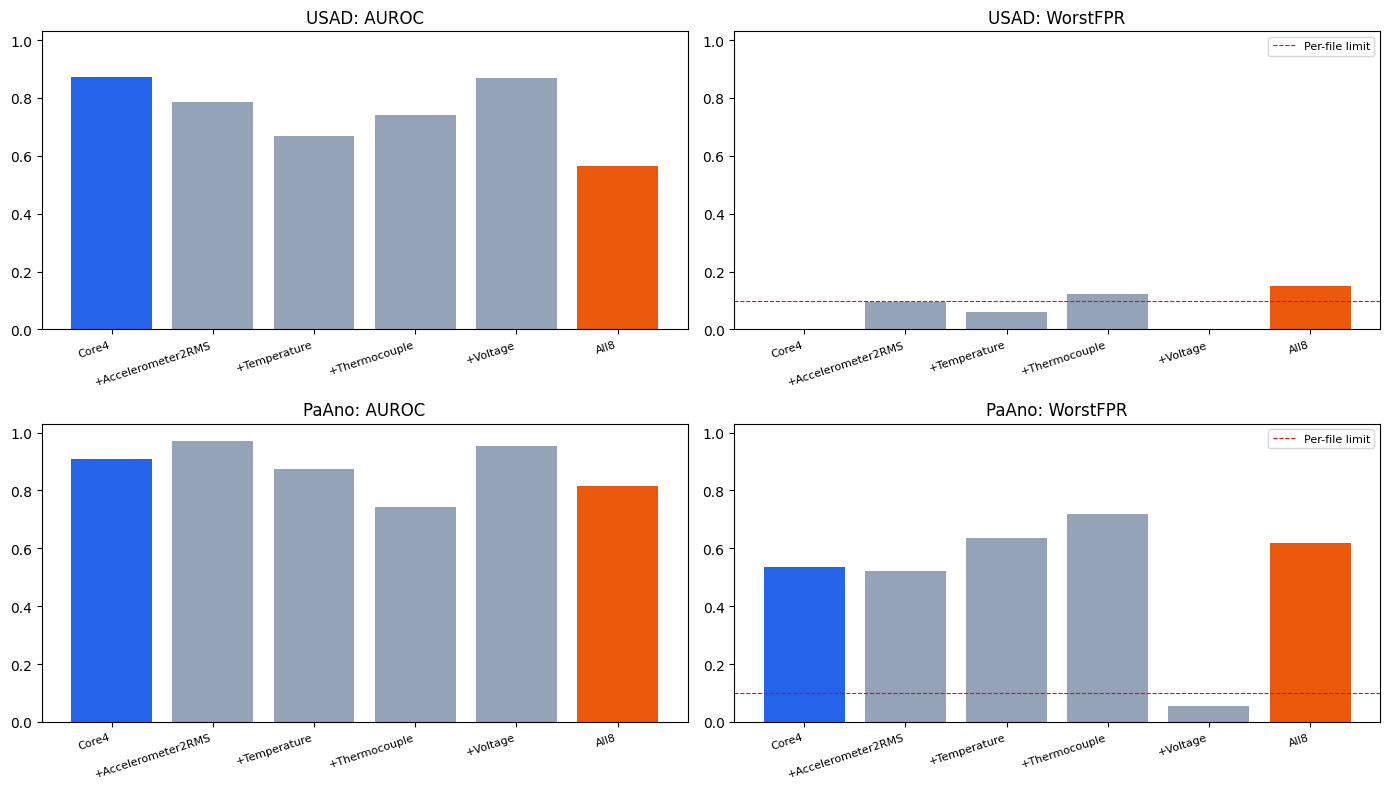

In [16]:
core_features = list(FEATURE_SETS["process4"])
extra_features = [feature for feature in FEATURES if feature not in core_features]
sensor_variants = [("Core4", core_features, "W32_process4")]
sensor_variants += [("+" + feature, core_features + [feature], None) for feature in extra_features]
sensor_variants += [("All8", list(FEATURES), "W32_all8")]
addback_rows = []
for method in ["USAD", "PaAno"]:
    for variant, features, cached_id in sensor_variants:
        for file_name, frame in development.items():
            if cached_id is not None:
                entry = cache[(cached_id, method, file_name)]
            else:
                design = {"input_id": variant, "window": 32, "sensors": "process4", "features": features}
                entry = fit_and_cache(frame, design, method, DEV_SEED)
            result = entry["pipeline"].operate(entry["raw"], OP_BY_ID[BASE_OPERATION])
            addback_rows.append({"method": method, "variant": variant, "file": file_name,
                                 **run_metrics(frame, result)})
sensor_addback = pd.DataFrame(addback_rows)
sensor_addback_summary = sensor_addback.groupby(["method", "variant"], sort=False).agg(
    F1=("F1", "mean"), AUROC=("AUROC", "mean"), FPR=("FPR", "mean"), WorstFPR=("FPR", "max")).reset_index()
display(sensor_addback_summary.round(4))
sensor_fig, sensor_axes = plt.subplots(2, 2, figsize=(14, 8))
variant_order = [variant for variant, _, _ in sensor_variants]
for row, method in enumerate(["USAD", "PaAno"]):
    table = sensor_addback_summary[sensor_addback_summary.method.eq(method)].set_index("variant").loc[variant_order]
    for ax, metric in zip(sensor_axes[row], ["AUROC", "WorstFPR"]):
        ax.bar(np.arange(len(table)), table[metric], color=["#2563eb"] + ["#94a3b8"] * 4 + ["#ea580c"])
        ax.set_xticks(np.arange(len(table)), variant_order, rotation=18, ha="right", fontsize=8)
        ax.set(title=f"{method}: {metric}", ylim=(0, 1.03))
        if metric == "WorstFPR":
            ax.axhline(FPR_LIMIT, color="red", ls="--", lw=0.8, label="Per-file limit")
            ax.legend(fontsize=8)
sensor_fig.tight_layout()
plt.show()
sensor_addback.to_csv(OUTPUT_DIR / "sensor_addback_trials.csv", index=False)
sensor_addback_summary.to_csv(OUTPUT_DIR / "sensor_addback_summary.csv", index=False)
sensor_fig.savefig(OUTPUT_DIR / "sensor_addback.png", dpi=140, bbox_inches="tight")

- 파란 막대는 핵심 4개, 회색 막대는 핵심 4개에 해당 센서 하나만 추가한 구성, 주황 막대는 전체 8개임
- 모든 비교에서 W32·같은 학습 구간·시드 42·99% 분위수·점별 경보를 사용함. 왼쪽 AUROC는 높을수록, 오른쪽 파일별 최악 FPR은 낮을수록 좋은 방향임
- 기존 4개·8개 구성은 저장된 모델을 사용하고, 센서를 하나씩 추가한 16개 모델만 별도로 학습함. 이 결과는 입력 효과를 이해하기 위한 개발 자료의 보조 비교임
- USAD에 온도만 추가하면 F1은 **0.3825→0.1786**, AUROC는 **0.8708→0.6692**로 낮아짐. 이번 모델에서 온도 추가가 점수 구분을 약하게 만든 비교 근거임
- 반대로 PaAno에 전압을 추가하면 F1은 **0.7478→0.7980**, FPR은 **41.11%→19.44%**로 개선됨. 전압이 모든 모델에서 방해가 되는 정보는 아니며, 센서 구성을 모델과 함께 선택할 필요가 있음

### Step 15-2: 원본 센서와 윈도 길이별 USAD 점수·경보 비교

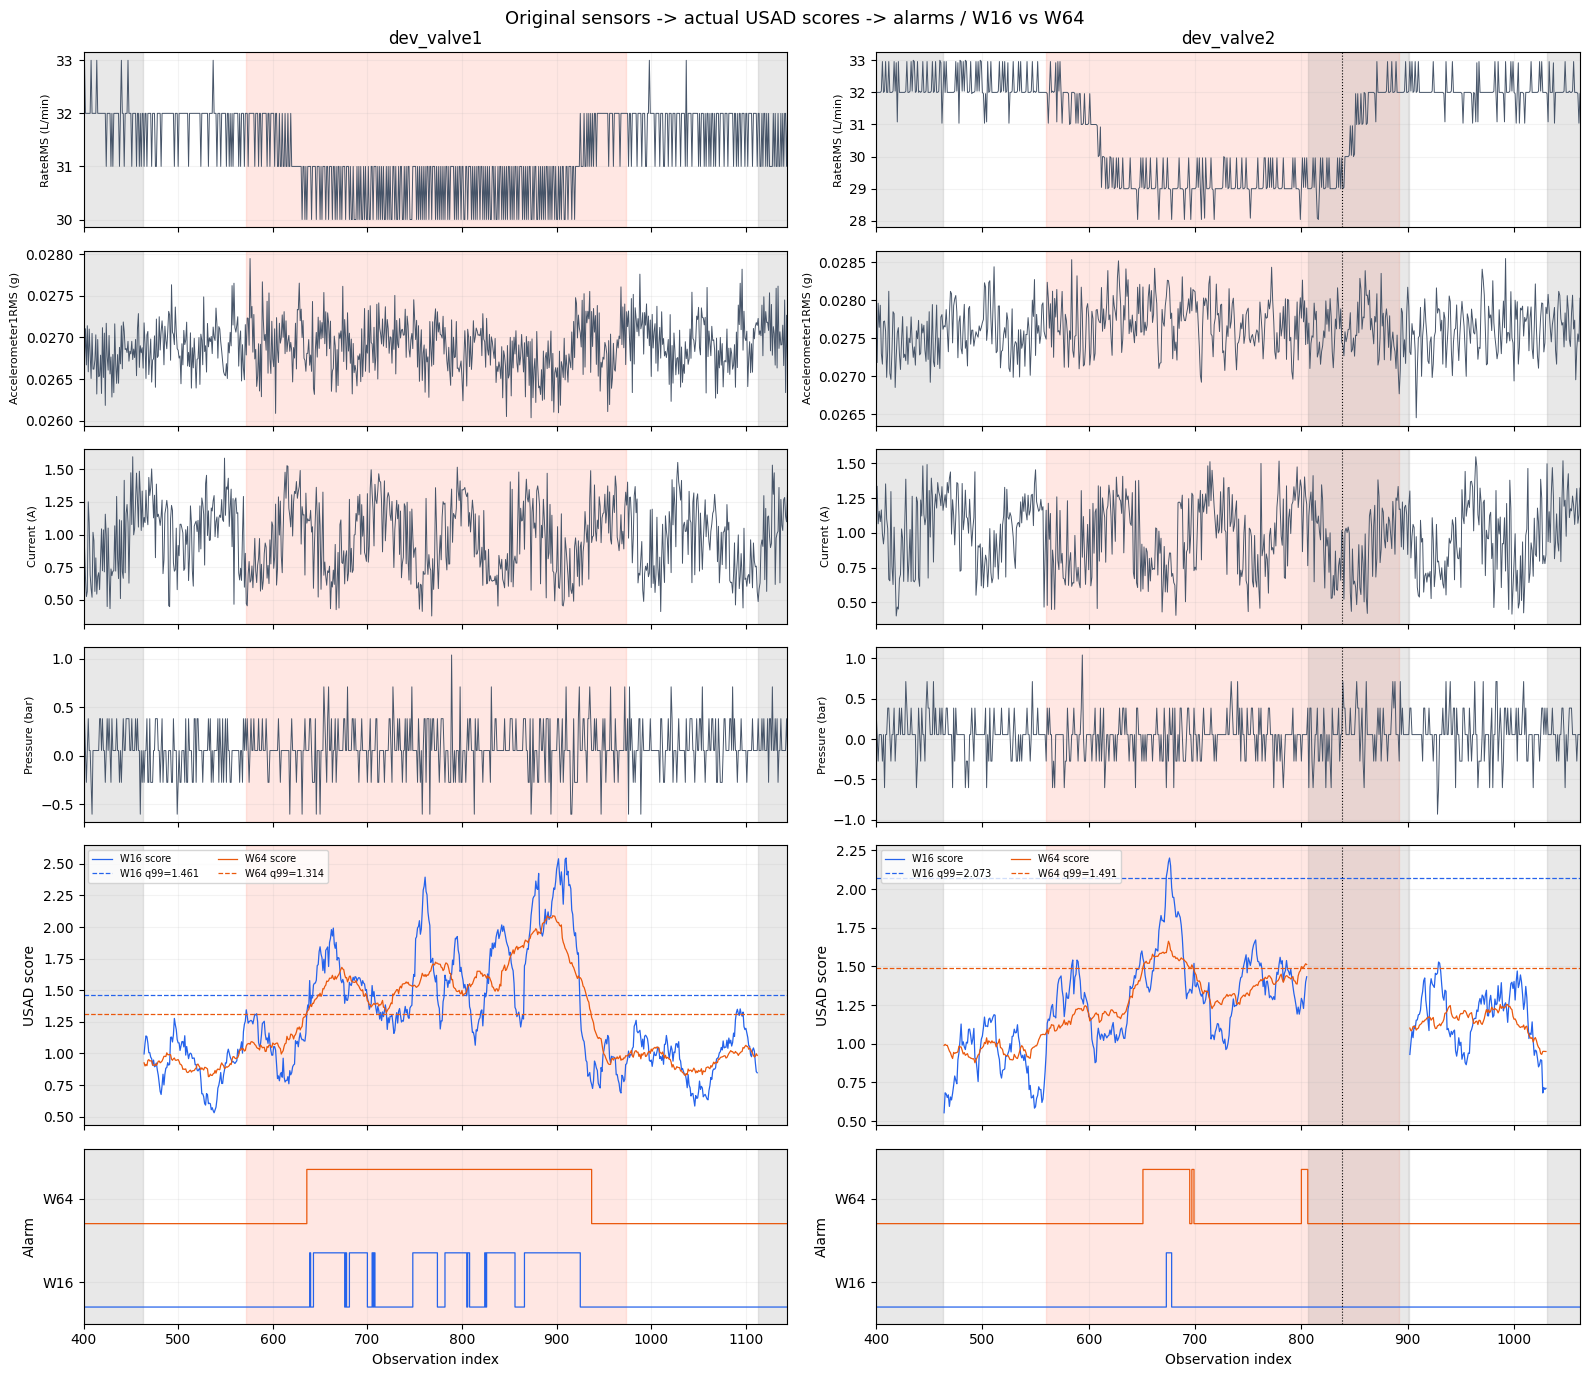

,file,window,q99_threshold,F1,Recall,FPR,AUROC
0,dev_valve1,16,1.4608,0.6578,0.4900,0.0,0.8694
1,dev_valve1,64,1.3140,0.8563,0.7488,0.0,0.9706
2,dev_valve2,16,2.0728,0.0296,0.0150,0.0,0.8066
3,dev_valve2,64,1.4910,0.2701,0.1562,0.0,0.9248


In [17]:
sensor_order = ["RateRMS", "Accelerometer1RMS", "Current", "Pressure"]
sensor_units = {"RateRMS": "L/min", "Accelerometer1RMS": "g", "Current": "A", "Pressure": "bar"}
window_fig, window_axes = plt.subplots(6, 2, figsize=(16, 14), sharex="col",
                                      gridspec_kw={"height_ratios": [1, 1, 1, 1, 1.6, 1]})
window_rows = []
for col, (file_name, frame) in enumerate(development.items()):
    part = frame.iloc[CALIB_END:]
    x, truth = part.index.to_numpy(), part.anomaly.to_numpy()
    ready = common_ranking_mask(frame)[CALIB_END:]
    for row, sensor in enumerate(sensor_order):
        ax = window_axes[row, col]
        ax.plot(x, part[sensor], color="#475569", lw=0.7)
        ax.set_ylabel(f"{sensor} ({sensor_units[sensor]})", fontsize=8)
    window_axes[0, col].set_title(file_name)
    score_ax, alarm_ax = window_axes[4, col], window_axes[5, col]
    for level, (window, color) in enumerate([(16, "#2563eb"), (64, "#ea580c")]):
        entry = cache[(f"W{window}_process4", "USAD", file_name)]
        result = entry["pipeline"].operate(entry["raw"], OP_BY_ID[BASE_OPERATION])
        assert np.array_equal(np.isfinite(result["score"]), ready)
        score_ax.plot(x, result["score"], color=color, lw=0.9, label=f"W{window} score")
        score_ax.axhline(result["high"], color=color, ls="--", lw=0.9,
                         label=f"W{window} q99={result['high']:.3f}")
        alarm_ax.step(x, level + 0.65 * result["prediction"], color=color, lw=0.9, where="post")
        window_rows.append({"file": file_name, "window": window, "q99_threshold": result["high"],
                            **run_metrics(frame, result)})
    score_ax.set_ylabel("USAD score")
    score_ax.legend(ncol=2, fontsize=7, loc="upper left")
    alarm_ax.set(yticks=[0.3, 1.3], yticklabels=["W16", "W64"], ylim=(-0.2, 1.9),
                 xlabel="Observation index", ylabel="Alarm")
    for ax in window_axes[:, col]:
        ax.fill_between(x, 0, 1, where=truth == 1, transform=ax.get_xaxis_transform(),
                        color="tomato", alpha=0.15)
        ax.fill_between(x, 0, 1, where=~ready, transform=ax.get_xaxis_transform(),
                        color="gray", alpha=0.18)
        for gap in frame.index[frame.datetime.diff().dt.total_seconds().gt(GAP_SECONDS)]:
            ax.axvline(gap, color="black", ls=":", lw=0.8)
        ax.set_xlim(x[0], x[-1])
        ax.grid(alpha=0.15)
window_fig.suptitle("Original sensors -> actual USAD scores -> alarms / W16 vs W64", fontsize=13)
window_fig.tight_layout()
plt.show()
window_score_summary = pd.DataFrame(window_rows)
display(window_score_summary[["file", "window", "q99_threshold", "F1", "Recall", "FPR", "AUROC"]].round(4))
window_score_summary.to_csv(OUTPUT_DIR / "window_score_alarm_comparison.csv", index=False)
window_fig.savefig(OUTPUT_DIR / "window_score_alarm_comparison.png", dpi=140, bbox_inches="tight")

- 위 4개 행은 모델에 입력한 유량·진동·전류·압력의 **원본 값**이며, 아래로 내려가면서 같은 시점의 USAD 점수와 경보를 연결하여 읽는 그림임
- 빨간 배경은 실제 이상 구간, 회색 배경은 공백·양끝 제외로 점수가 없는 구간임. 유량이 낮아진 구간에서 다른 센서와 점수가 함께 어떻게 바뀌는지 확인함
- 점수 그림의 파란 실선은 W16, 주황 실선은 W64이며 같은 색의 점선은 각 모델의 정상 보정 99% 분위수임. 맨 아래는 점수가 해당 임계값을 넘으면 ON이 되는 경보임
- W64는 더 많은 관측의 오차를 평균하므로 짧은 변동이 완만해짐. 이번 자료에서는 낮아진 유량이 오래 이어져, 정상과 이상 점수의 구분이 W16보다 좋아지는 모습을 확인함
- 두 개발 파일 평균 AUROC는 W16 **0.8380**에서 W64 **0.9477**로, F1은 **0.3437→0.5632**로 높아짐. FPR은 두 구성 모두 **0%**이므로 이번 개선은 오경보 감소보다 놓친 이상을 더 많이 탐지한 결과임
- W16·W64는 각각 학습한 모델이며 각자의 정상 보정 점수로 임계값을 정함. 원본 신호의 변화가 점수와 경보로 이어지는 전체 입력설계 효과를 비교함
- valve1에서 W16은 높은 점수 구간 사이에 경보가 자주 끊기지만 W64는 낮아진 유량 구간에서 경보가 더 이어짐. 재현율은 **49.00%→74.88%**, F1은 **0.6578→0.8563**임
- valve2에서는 정상 보정 임계값도 W16 **2.0728**, W64 **1.4910**으로 달라짐. W16은 높은 봉우리 일부만 넘고 W64는 더 넓은 구간에서 넘어, 재현율이 **1.50%→15.62%**로 높아짐. 같은 99% 기준이라도 실제 점수와 보정 임계값을 함께 확인할 필요가 있음

### 8-3) 운영규칙의 효과

- 개발에서 선정된 **복원 기반 USAD·윈도 64개 관측(W64)·공정 핵심 4개 센서**를 고정함. 센서는 `Accelerometer1RMS`·`Current`·`Pressure`·`RateRMS`임
- 같은 모델 점수에서 정상 보정 분위수·EMA·경보 규칙만 바꾸어 18개 운영안을 비교함
- Step 16은 개발 파일 `valve1/1.csv`와 `valve2/1.csv`의 **파일별 지표를 같은 비중으로 평균**한 결과이며, Step 16-1은 대표 규칙 5개를 **파일별로 구분**한 결과임

### Step 16: 운영 규칙의 민감도와 지연 비교

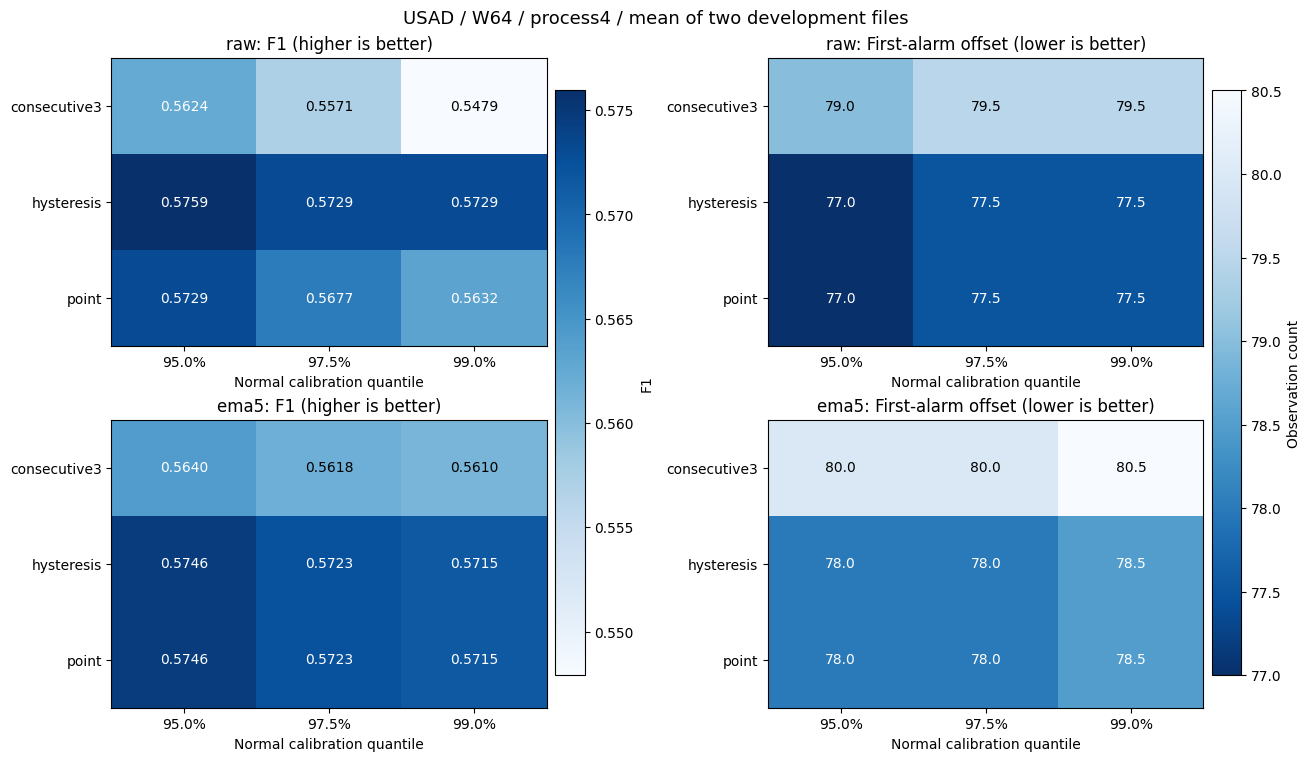

,q,smoothing,trigger,F1,FPR,EventRecall,MeanDelayObs,MeanDelaySeconds,FalseAlarmEvents
310,0.950,raw,hysteresis,0.5759,0.0,1.0,77.0,81.5,0.0
307,0.950,ema5,hysteresis,0.5746,0.0,1.0,78.0,82.5,0.0
308,0.950,ema5,point,0.5746,0.0,1.0,78.0,82.5,0.0
322,0.990,raw,hysteresis,0.5729,0.0,1.0,77.5,82.0,0.0
311,0.950,raw,point,0.5729,0.0,1.0,77.0,81.5,0.0
316,0.975,raw,hysteresis,0.5729,0.0,1.0,77.5,82.0,0.0
314,0.975,ema5,point,0.5723,0.0,1.0,78.0,82.5,0.0
313,0.975,ema5,hysteresis,0.5723,0.0,1.0,78.0,82.5,0.0
319,0.990,ema5,hysteresis,0.5715,0.0,1.0,78.5,83.0,0.0
320,0.990,ema5,point,0.5715,0.0,1.0,78.5,83.0,0.0


In [18]:
operation_view = comparison[comparison.input_id.eq(best_development.input_id) & comparison.method.eq(best_development.method)]
metrics = ["F1", "MeanDelayObs"]
color_ranges = {}
for metric in metrics:
    low, high = float(operation_view[metric].min()), float(operation_view[metric].max())
    if low == high:
        low, high = low - 1e-6, high + 1e-6
    color_ranges[metric] = (low, high)

operation_fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), layout="constrained")
for col, metric in enumerate(metrics):
    low, high = color_ranges[metric]
    for row, mode in enumerate(["raw", "ema5"]):
        matrix = operation_view[operation_view.smoothing.eq(mode)].pivot(index="trigger", columns="q", values=metric)
        ax = axes[row, col]
        heatmap = ax.imshow(matrix, vmin=low, vmax=high, cmap="Blues" if metric == "F1" else "Blues_r", aspect="auto")
        ax.set_xticks(range(len(matrix.columns)), [f"{q:.1%}" for q in matrix.columns])
        ax.set_yticks(range(len(matrix.index)), matrix.index)
        for i in range(len(matrix.index)):
            for j in range(len(matrix.columns)):
                value = float(matrix.iloc[i, j])
                fraction = (value - low) / (high - low)
                dark = fraction > 0.5 if metric == "F1" else fraction < 0.5
                ax.text(j, i, f"{value:.4f}" if metric == "F1" else f"{value:.1f}", ha="center", va="center",
                        color="white" if dark else "black")
        title = "F1 (higher is better)" if metric == "F1" else "First-alarm offset (lower is better)"
        ax.set(title=f"{mode}: {title}", xlabel="Normal calibration quantile")
    operation_fig.colorbar(heatmap, ax=axes[:, col].tolist(), shrink=0.9, pad=0.02,
                          label="F1" if metric == "F1" else "Observation count")
operation_fig.suptitle("USAD / W64 / process4 / mean of two development files", fontsize=13)
plt.show()
display(operation_view[["q", "smoothing", "trigger", "F1", "FPR", "EventRecall", "MeanDelayObs", "MeanDelaySeconds", "FalseAlarmEvents"]]
        .sort_values("F1", ascending=False).round(4))

- 가로축은 정상 보정 분위수, 세로축은 경보 규칙임. 위쪽은 원점수, 아래쪽은 EMA5이며 왼쪽은 F1, 오른쪽은 최초 경보까지의 관측 수임
- 색은 18개 운영안에서 실제 관측된 최솟값~최댓값에 맞춤. F1은 **0.5479~0.5759**, 경보 위치 차이는 **77.0~80.5개 관측** 범위이며 두 지표 모두 **진한 파란색이 유리한 방향**임
- 같은 지표의 원점수·EMA5 그림은 공통 색 범위를 사용함. 오른쪽 색상 막대에서 실제 값과 색의 관계를 확인하며, 좁은 범위를 확대해 표시한 만큼 차이의 크기는 칸 안의 숫자로 함께 확인함
- 그림과 표는 두 파일의 지표를 각각 계산한 뒤 평균한 값임. 95%·원점수·점별 경보의 F1은 **(0.8580+0.2879)/2=0.5729**, 최초 경보 위치 차이는 **(63+91)/2=77개 관측**임
- 운영안 18개 모두 개발 FPR **0%**, 이벤트 재현율 **1.0**임. 이번에는 이상 구간 내 탐지 유지와 반응 시점의 차이를 비교함
- 점별→3연속에서 F1은 **0.5729→0.5624**, 최초 경보 위치 차이는 **77→79개 관측**임. 점별→히스테리시스의 F1은 **0.5729→0.5759**임
- 원점수→EMA5의 히스테리시스 F1은 **0.5759→0.5746**, 최초 경보 위치 차이는 **77→78개 관측**임. 아래 확대 그림에서 파일별 경보 위치 차이를 확인함

### Step 16-1: 경보 진입과 해제 구간을 확대하여 비교

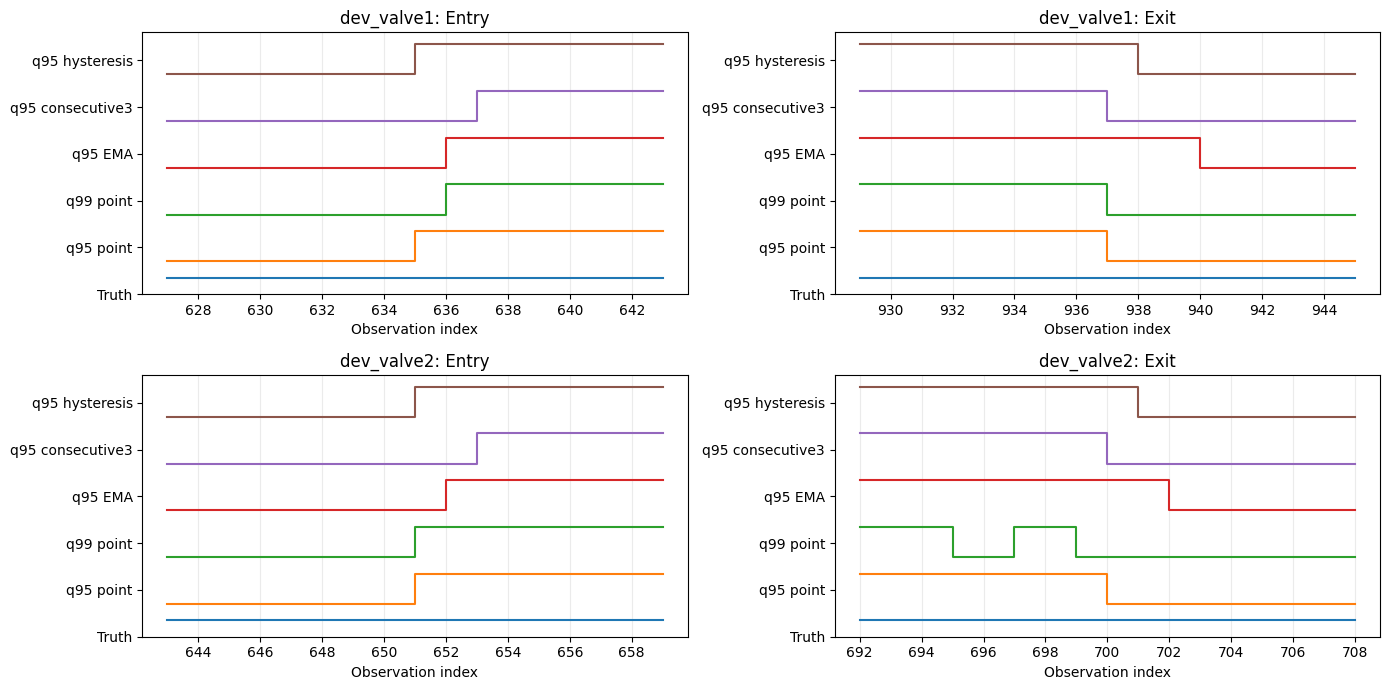

,file,rule,F1,Recall,FPR,MeanDelayObs
0,dev_valve1,q95 point,0.8580,0.7512,0.0,63.0
1,dev_valve1,q99 point,0.8563,0.7488,0.0,64.0
2,dev_valve1,q95 EMA,0.8612,0.7562,0.0,64.0
3,dev_valve1,q95 consecutive3,0.8547,0.7463,0.0,65.0
4,dev_valve1,q95 hysteresis,0.8596,0.7537,0.0,63.0
5,dev_valve2,q95 point,0.2879,0.1682,0.0,91.0
6,dev_valve2,q99 point,0.2701,0.1562,0.0,91.0
7,dev_valve2,q95 EMA,0.2879,0.1682,0.0,92.0
8,dev_valve2,q95 consecutive3,0.2701,0.1562,0.0,93.0
9,dev_valve2,q95 hysteresis,0.2923,0.1712,0.0,91.0


In [19]:
rule_examples = [("q95 point", "q0.95_raw_point"), ("q99 point", "q0.99_raw_point"),
                 ("q95 EMA", "q0.95_ema5_point"), ("q95 consecutive3", "q0.95_raw_consecutive3"),
                 ("q95 hysteresis", "q0.95_raw_hysteresis")]
rule_fig, rule_axes = plt.subplots(2, 2, figsize=(14, 7), squeeze=False)
rule_rows = []
for row, (file_name, frame) in enumerate(development.items()):
    entry = cache[("W64_process4", "USAD", file_name)]
    part = frame.iloc[CALIB_END:]
    truth, x = part.anomaly.to_numpy(), part.index.to_numpy()
    results = {label: entry["pipeline"].operate(entry["raw"], OP_BY_ID[operation_id])
               for label, operation_id in rule_examples}
    baseline = results["q95 point"]["prediction"]
    positive = np.flatnonzero(baseline)
    endings = np.flatnonzero(results["q95 hysteresis"]["prediction"] != baseline)
    centers = [positive[0], endings[-1] if len(endings) else positive[-1]]
    for ax, center, stage in zip(rule_axes[row], centers, ["Entry", "Exit"]):
        selected = (np.arange(len(part)) >= center - 8) & (np.arange(len(part)) <= center + 8)
        sequences = [("Truth", truth)] + [(label, results[label]["prediction"]) for label, _ in rule_examples]
        for level, (label, prediction) in enumerate(sequences):
            ax.step(x[selected], level + 0.65 * prediction[selected], where="post", label=label)
        ax.set(yticks=np.arange(len(sequences)) + 0.3, yticklabels=[label for label, _ in sequences],
               xlabel="Observation index", title=f"{file_name}: {stage}")
        ax.grid(axis="x", alpha=0.25)
    for label, result in results.items():
        rule_rows.append({"file": file_name, "rule": label, **run_metrics(frame, result)})
rule_fig.tight_layout()
plt.show()
rule_sample_summary = pd.DataFrame(rule_rows)
display(rule_sample_summary[["file", "rule", "F1", "Recall", "FPR", "MeanDelayObs"]].round(4))
rule_sample_summary.to_csv(OUTPUT_DIR / "operation_sample_summary.csv", index=False)
rule_fig.savefig(OUTPUT_DIR / "operation_entry_exit.png", dpi=140, bbox_inches="tight")

- 각 줄의 낮은 위치는 경보 OFF, 높은 위치는 ON임. 정답 줄과 같은 시간축에서 규칙별 진입·해제를 비교함
- 왼쪽에서 3연속은 점별 경보보다 **2개 관측**, EMA는 **1개 관측** 뒤에 켜지는 모습을 확인함
- 오른쪽에서 히스테리시스가 점별 경보보다 **1개 관측** 더 유지되는 위치를 확인함. 시작 임계값 아래로 내려가도 종료 임계값 위에서는 경보를 유지하는 동작임
- Step 16의 표는 운영안 18개의 두 파일 평균이며, 이 표는 그중 대표 규칙 5개를 valve1·valve2별로 나눈 10개 결과임. 확대 그림과 달리 표의 지표는 각 파일의 전체 평가 구간에서 계산함. 여기서 비교한 규칙의 FPR은 모두 0%임

### 8-4) 방법설계의 효과와 정상 점수 분포

- 공통 입력·운영 규칙의 결과와 각 모델에 맞추어 입력·운영까지 선정한 결과를 비교함
- 정상 검증·보정 구간의 점수 분포에서 임계값을 정할 때 고려할 차이를 확인함

### Step 17: 방법별 기본안·선정안과 정상 검증·보정 점수 확인

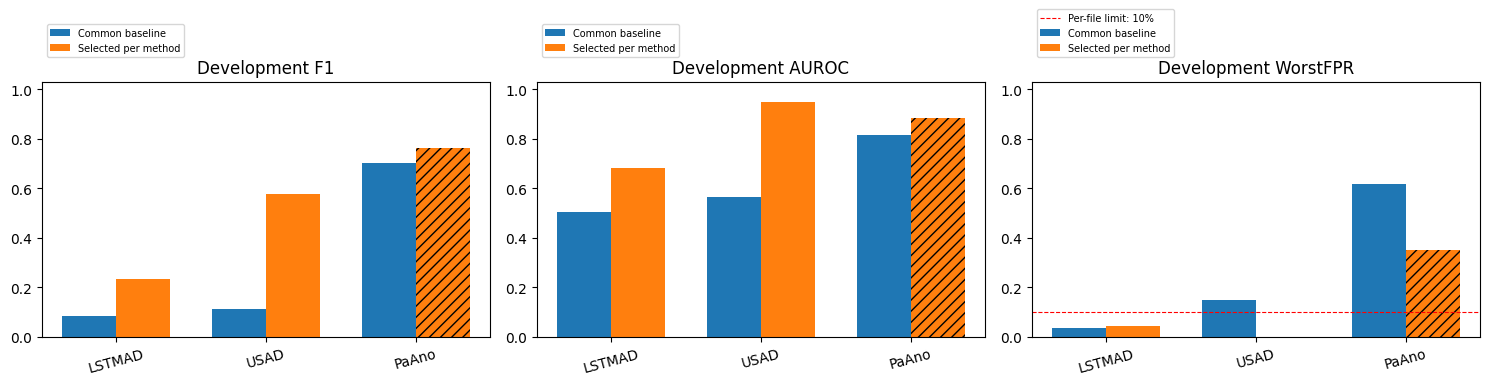

,method,input_id,operation_id,feasible,F1,FPR,WorstFPR,AP,AUROC
271,LSTMAD,W64_process4,q0.95_ema5_hysteresis,True,0.2332,0.0279,0.0437,0.7199,0.6821
310,USAD,W64_process4,q0.95_raw_hysteresis,True,0.5759,0.0000,0.0000,0.9626,0.9477
84,PaAno,W16_process4,q0.99_ema5_consecutive3,False,0.7616,0.1962,0.3515,0.9436,0.8861


/tmp/ipykernel_3069140/84279939.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(distributions, labels=["Normal valid (80)", "Calibration (48)"])
/tmp/ipykernel_3069140/84279939.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(distributions, labels=["Normal valid (80)", "Calibration (48)"])
/tmp/ipykernel_3069140/84279939.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(distributions, labels=["Normal valid (80)", "Calibration (48)"])


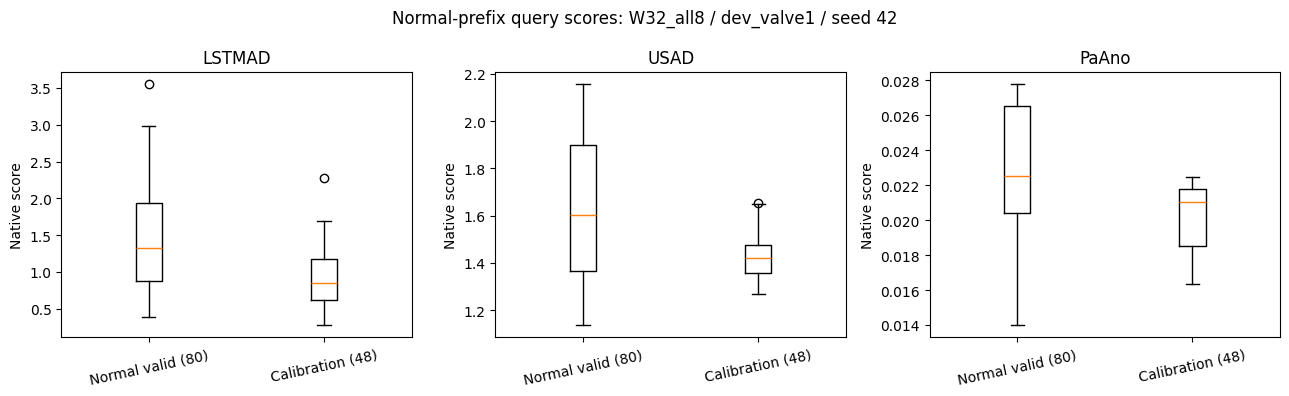

,method,role,n,Q1,median,Q3,q95,q99
0,LSTMAD,Normal valid,80,0.8746,1.3227,1.9424,2.6291,3.1056
1,LSTMAD,Calibration,48,0.6211,0.8545,1.1748,1.6228,2.0002
2,USAD,Normal valid,80,1.3636,1.6042,1.9003,2.1395,2.1572
3,USAD,Calibration,48,1.3565,1.4210,1.4743,1.6387,1.6505
4,PaAno,Normal valid,80,0.0204,0.0225,0.0265,0.0278,0.0278
5,PaAno,Calibration,48,0.0185,0.0210,0.0218,0.0224,0.0225


,method,input_id,file,native_class,calibration_points,fit_seconds
0,LSTMAD,W16_all8,dev_valve1,TSB_AD.models.LSTMAD.LSTMAD,48,0.1311
1,LSTMAD,W16_all8,dev_valve2,TSB_AD.models.LSTMAD.LSTMAD,48,0.1336
2,USAD,W16_all8,dev_valve1,TSB_AD.models.USAD.USAD,48,0.2333
3,USAD,W16_all8,dev_valve2,TSB_AD.models.USAD.USAD,48,0.1488
4,PaAno,W16_all8,dev_valve1,TSB_AD.models.PaAno_PAI.PaAno_PAI,48,0.5333
5,PaAno,W16_all8,dev_valve2,TSB_AD.models.PaAno_PAI.PaAno_PAI,48,0.1597
6,LSTMAD,W16_process4,dev_valve1,TSB_AD.models.LSTMAD.LSTMAD,48,0.1379
7,LSTMAD,W16_process4,dev_valve2,TSB_AD.models.LSTMAD.LSTMAD,48,0.1529
8,USAD,W16_process4,dev_valve1,TSB_AD.models.USAD.USAD,48,0.1569
9,USAD,W16_process4,dev_valve2,TSB_AD.models.USAD.USAD,48,0.1538


In [20]:
family_best = pd.DataFrame([select_best(comparison[comparison.method.eq(method)]) for method in MODEL_REGISTRY])
baseline_methods = comparison[comparison.input_id.eq(BASE_INPUT) & comparison.operation_id.eq(BASE_OPERATION)]
method_fig, axes = plt.subplots(1, 3, figsize=(15, 4))
position = np.arange(3)
for ax, metric in zip(axes, ["F1", "AUROC", "WorstFPR"]):
    baseline = baseline_methods.set_index("method").reindex(MODEL_REGISTRY)
    selected = family_best.set_index("method").reindex(MODEL_REGISTRY)
    ax.bar(position - 0.18, baseline[metric], width=0.36, label="Common baseline")
    bars = ax.bar(position + 0.18, selected[metric], width=0.36, label="Selected per method")
    for bar, feasible in zip(bars, selected.feasible):
        if not feasible:
            bar.set_hatch("///")
    if metric == "WorstFPR":
        ax.axhline(FPR_LIMIT, color="red", ls="--", lw=0.8, label="Per-file limit: 10%")
    ax.set_xticks(position, list(MODEL_REGISTRY), rotation=15)
    ax.set(title=f"Development {metric}", ylim=(0, 1.03))
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), fontsize=7)
method_fig.tight_layout()
plt.show()
display(family_best[["method", "input_id", "operation_id", "feasible", "F1", "FPR", "WorstFPR", "AP", "AUROC"]].round(4))
validation_fig, axes = plt.subplots(1, 3, figsize=(13, 4))
normal_score_rows = []
for ax, method in zip(axes, MODEL_REGISTRY):
    pipeline = cache[(BASE_INPUT, method, "dev_valve1")]["pipeline"]
    distributions = [pipeline.prefix_scores[TRAIN_END:VALID_END], pipeline.prefix_scores[VALID_END:CALIB_END]]
    distributions = [values[np.isfinite(values)] for values in distributions]
    ax.boxplot(distributions, labels=["Normal valid (80)", "Calibration (48)"])
    ax.set(title=method, ylabel="Native score")
    ax.tick_params(axis="x", rotation=12)
    for role, values in zip(["Normal valid", "Calibration"], distributions):
        normal_score_rows.append({"method": method, "role": role, "n": len(values),
                                  "Q1": np.quantile(values, 0.25), "median": np.median(values),
                                  "Q3": np.quantile(values, 0.75), "q95": np.quantile(values, 0.95),
                                  "q99": np.quantile(values, 0.99)})
validation_fig.suptitle(f"Normal-prefix query scores: {BASE_INPUT} / dev_valve1 / seed {DEV_SEED}")
validation_fig.tight_layout()
plt.show()
normal_score_summary = pd.DataFrame(normal_score_rows)
display(normal_score_summary.round(4))
normal_score_summary.to_csv(OUTPUT_DIR / "normal_score_distribution.csv", index=False)
display(fit_log[["method", "input_id", "file", "native_class", "calibration_points", "fit_seconds"]].round(4))

- 첫 막대는 **W32·전체 8개·99%·원점수·점별 경보**, 두 번째 막대는 방법별 선정안임. USAD의 F1 **0.1118→0.5759**는 입력·모델·운영을 함께 설계한 효과임
- 방법별 선정 F1은 LSTMAD **0.2332**, USAD **0.5759**, PaAno **0.7899**임. PaAno의 최악 파일 FPR **26.97%**가 요구 수준을 넘어, 조건을 충족한 USAD를 선정함. 사선은 제약 미달인 막대임

**정상 점수 상자그림**

- W32·전체 8개에서 정상 검증 위치 80개와 보정 위치 48개의 점수 분포를 비교한 그림임
- 중앙선은 중앙값, 상자의 아래·위는 25%·75% 분위수임. 수염은 상자 경계에서 상자 길이의 1.5배 이내인 관측까지 이어지며 바깥 점도 정상 자료에서 나온 값임
- 검증→보정 중앙값은 LSTMAD **1.3227→0.8545**, USAD **1.6042→1.4210**, PaAno **0.03495→0.03275**임. 정상 구간 안에서도 점수 분포가 달라지는 모습을 확인함
- 같은 모델 안에서 상자 위치와 높은 분위수를 비교함. 예를 들어 LSTMAD의 99% 분위수는 **3.1056→2.0002**여서 어떤 정상 구간으로 임계값을 정했는지가 경보 기준에 영향을 줌

### Step 18: 시험 전에 구성과 선정 근거 고정

In [21]:
def recipe_from_row(row):
    return {"input": dict(INPUT_BY_ID[row.input_id]), "method": row.method,
            "operation": dict(OP_BY_ID[row.operation_id]), "development_F1": float(row.F1),
            "development_FPR": float(row.FPR), "development_worst_FPR": float(row.WorstFPR),
            "meets_development_requirement": bool(row.feasible)}

frozen = {"selected": recipe_from_row(best_development),
          "per_method": {method: recipe_from_row(select_best(comparison[comparison.method.eq(method)])) for method in MODEL_REGISTRY},
          "development_files": DEV_FILES, "test_files": TEST_FILES, "test_seeds": TEST_SEEDS,
          "split": [TRAIN_END, VALID_END, CALIB_END], "gap_seconds": GAP_SECONDS, "common_edges": [EDGE_LEFT,EDGE_RIGHT],
          "evaluation_scope": "offline native API", "native_models": ["LSTMAD","USAD","PaAno_PAI/public_pai"],
          "fpr_limit_per_development_file": FPR_LIMIT, "source_commits": {"SKAB": SKAB_SHA, "TSB-AD": TSB_SHA}}
frozen_text = json.dumps(frozen, ensure_ascii=False, indent=2)
(OUTPUT_DIR / "frozen_design.json").write_text(frozen_text, encoding="utf-8")
frozen_hash = hashlib.sha256((OUTPUT_DIR / "frozen_design.json").read_bytes()).hexdigest()
print("Selected:", frozen["selected"])
print("Frozen design SHA256:", frozen_hash)
print("Meets development requirement:", frozen["selected"]["meets_development_requirement"])

Selected: {'input': {'input_id': 'W64_process4', 'window': 64, 'sensors': 'process4'}, 'method': 'USAD', 'operation': {'operation_id': 'q0.95_raw_hysteresis', 'q': 0.95, 'smoothing': 'raw', 'trigger': 'hysteresis'}, 'development_F1': 0.5759410801963993, 'development_FPR': 0.0, 'development_worst_FPR': 0.0, 'meets_development_requirement': True}
Frozen design SHA256: fbafd9ccb646e39aee74c27edf0a7632643349a0435b0d8c4f948b5871fbb406
Meets development requirement: True


- 개발 결과에서 선정한 입력·모델·운영 규칙과 파일 역할을 저장하고, 다음 시험에서는 이 설정을 적용함

### 8-5) 선정된 설계의 최종 시험

- 별도 시험 파일마다 초기 정상 자료로 학습·검증·임계값 보정을 수행한 뒤 이후 구간을 평가함
- 모델별 선정안 3개×시험 파일 3개×시드 3개로 **27회 평가**를 수행함
- 항상 정상·항상 경보인 기준선과 비교하고 파일별 성능과 세 시드의 변동을 확인함

### Step 19: 별도 시험 파일에서 고정된 설계 평가

In [22]:
testing = {name: load_skab(path) for name, path in TEST_FILES.items()}
test_rows, baseline_rows, final_entries, test_scored = [], [], {}, {}
for method, recipe in frozen["per_method"].items():
    for file_name, frame in testing.items():
        for seed in TEST_SEEDS:
            entry = fit_and_cache(frame, recipe["input"], method, seed)
            result = entry["pipeline"].operate(entry["raw"], recipe["operation"])
            test_scored[(method,file_name,seed)] = {**entry,"result":result}
            test_rows.append({"method": method, "file": file_name, "seed": seed,
                              "selected_global_method": method == frozen["selected"]["method"],
                              "input_id": recipe["input"]["input_id"], "operation_id": recipe["operation"]["operation_id"],
                              "high": result["high"], "low": result["low"], **run_metrics(frame, result)})
            saved = frame.iloc[CALIB_END:][["datetime", "anomaly"]].copy()
            saved["raw_score"] = entry["raw"][CALIB_END:]
            saved["score"], saved["prediction"] = result["score"], result["prediction"]
            saved["ranking_eligible"] = common_ranking_mask(frame)[CALIB_END:]
            saved["score_available"] = np.isfinite(result["score"])
            saved["data_quality_alarm"] = frame.datetime.diff().dt.total_seconds().gt(GAP_SECONDS).iloc[CALIB_END:].to_numpy()
            saved.to_csv(OUTPUT_DIR / f"{file_name}_{method}_seed{seed}.csv", index=False)
            if seed == DEV_SEED:
                final_entries[(method, file_name)] = {**entry, "result": result}
        print("Final evaluation:", method, file_name, flush=True)
for file_name, frame in testing.items():
    part = frame.iloc[CALIB_END:]
    for label, constant in [("Always normal", 0), ("Always alarm", 1)]:
        prediction = np.full(len(part), constant)
        baseline_rows.append({"method": label, "file": file_name,
                              **evaluate(part.anomaly.to_numpy(), prediction, prediction.astype(float),
                                         time=part.datetime.to_numpy(), ranking_mask=common_ranking_mask(frame)[CALIB_END:])})
test_results, baselines = pd.DataFrame(test_rows), pd.DataFrame(baseline_rows)
test_summary = test_results.groupby(["method", "file"])[["Accuracy", "F1", "FPR", "AUROC", "AP", "EventRecall", "MeanDelayObs", "MeanDelaySeconds", "ScoredCoverage"]].agg(["mean", "std"])
display(test_summary.round(4))
display(baselines[["method", "file", "Accuracy", "F1", "FPR", "EventRecall"]].round(4))
assert hashlib.sha256((OUTPUT_DIR / "frozen_design.json").read_bytes()).hexdigest() == frozen_hash
test_results.to_csv(OUTPUT_DIR / "final_test_runs.csv", index=False)
baselines.to_csv(OUTPUT_DIR / "final_test_baselines.csv", index=False)
test_summary.to_csv(OUTPUT_DIR / "final_test_summary.csv")

Final evaluation: LSTMAD test_valve1
Final evaluation: LSTMAD test_valve2
Final evaluation: LSTMAD test_other
Final evaluation: USAD test_valve1
Final evaluation: USAD test_valve2
Final evaluation: USAD test_other
Final evaluation: PaAno test_valve1
Final evaluation: PaAno test_valve2
Final evaluation: PaAno test_other


Accuracy              F1             FPR           AUROC  \
                       mean     std    mean     std    mean     std    mean   
method file                                                                   
LSTMAD test_other    0.5124  0.0258  0.2957  0.0277  0.1082  0.0385  0.4761   
       test_valve1   0.5037  0.0053  0.0380  0.0225  0.0138  0.0123  0.5643   
       test_valve2   0.5624  0.0453  0.4079  0.0964  0.1068  0.0069  0.6399   
PaAno  test_other    0.9448  0.0228  0.9504  0.0194  0.0885  0.0491  0.9619   
       test_valve1   0.5412  0.0384  0.2183  0.2553  0.0888  0.1537  0.4986   
       test_valve2   0.8390  0.0635  0.8496  0.0512  0.1557  0.2645  0.9125   
USAD   test_other    0.7806  0.0055  0.7451  0.0080  0.0000  0.0000  0.9325   
       test_valve1   0.5007  0.0000  0.0000  0.0000  0.0000  0.0000  0.9905   
       test_valve2   0.9049  0.0029  0.9139  0.0024  0.1267  0.0062  0.9600   

                                AP         EventRecall      MeanDelayObs  \
                       std    mean     std        mean  std         mean   
method file                                                                
LSTMAD test_other   0.0791  0.6301  0.0595         1.0  0.0       7.0000   
       test_valve1  0.0469  0.5969  0.0372         1.0  0.0      97.3333   
       test_valve2  0.0545  0.7398  0.0402         1.0  0.0      18.0000   
PaAno  test_other   0.0261  0.9579  0.0333         1.0  0.0      10.6667   
       test_valve1  0.2055  0.6388  0.1474         1.0  0.0     135.6667   
       test_valve2  0.0535  0.9589  0.0242         1.0  0.0      36.3333   
USAD   test_other   0.0007  0.9595  0.0005         1.0  0.0       1.0000   
       test_valve1  0.0001  0.9936  0.0001         0.0  0.0          NaN   
       test_valve2  0.0005  0.9788  0.0002         1.0  0.0      24.0000   

                             MeanDelaySeconds           ScoredCoverage       
                         std             mean       std           mean  std  
method file                                                                  
LSTMAD test_other     0.0000           7.0000    0.0000         0.8697  0.0  
       test_valve1   11.5470         103.0000   12.1244         0.7156  0.0  
       test_valve2    0.0000          19.0000    0.0000         0.8683  0.0  
PaAno  test_other     3.5119          11.3333    4.0415         0.8697  0.0  
       test_valve1  109.6008         143.3333  115.1057         0.7156  0.0  
       test_valve2   33.8575          39.0000   36.3731         0.8683  0.0  
USAD   test_other     0.0000           1.0000    0.0000         0.8697  0.0  
       test_valve1       NaN              NaN       NaN         0.7156  0.0  
       test_valve2    0.0000          26.0000    0.0000         0.8683  0.0

,method,file,Accuracy,F1,FPR,EventRecall
0,Always normal,test_valve1,0.5007,0.0000,0.0,0.0
1,Always alarm,test_valve1,0.4993,0.6660,1.0,1.0
2,Always normal,test_valve2,0.4582,0.0000,0.0,0.0
3,Always alarm,test_valve2,0.5418,0.7028,1.0,1.0
4,Always normal,test_other,0.4600,0.0000,0.0,0.0
5,Always alarm,test_other,0.5400,0.7013,1.0,1.0


- F1·FPR은 점수가 없는 관측도 포함한 전체 평가 구간으로 계산함. 점수가 없는 이상 관측은 미탐으로 반영됨
- AUROC는 모든 모델에서 점수가 유효한 같은 관측으로 계산함. 점수 제공률과 함께 확인함

### Step 20: 최종 성능·경보 파형과 오류 위치 확인

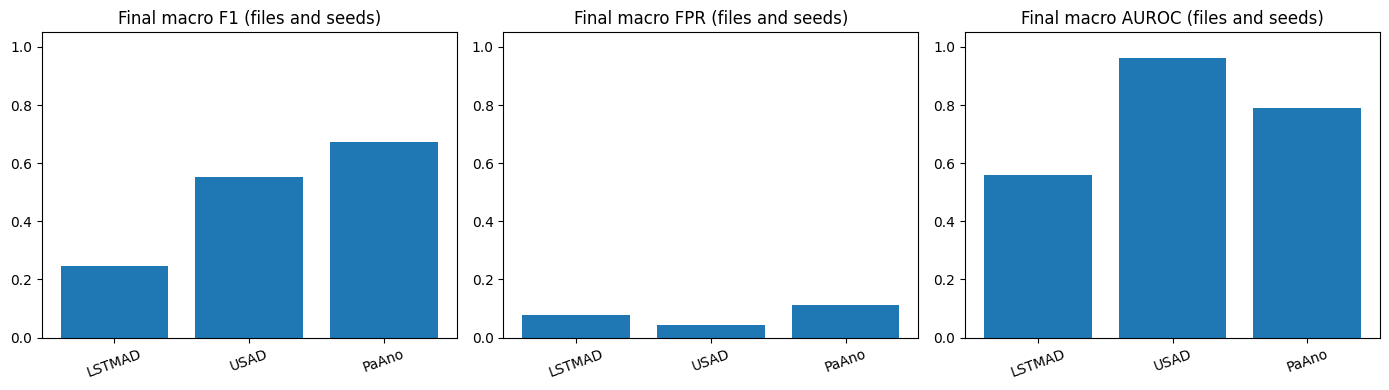

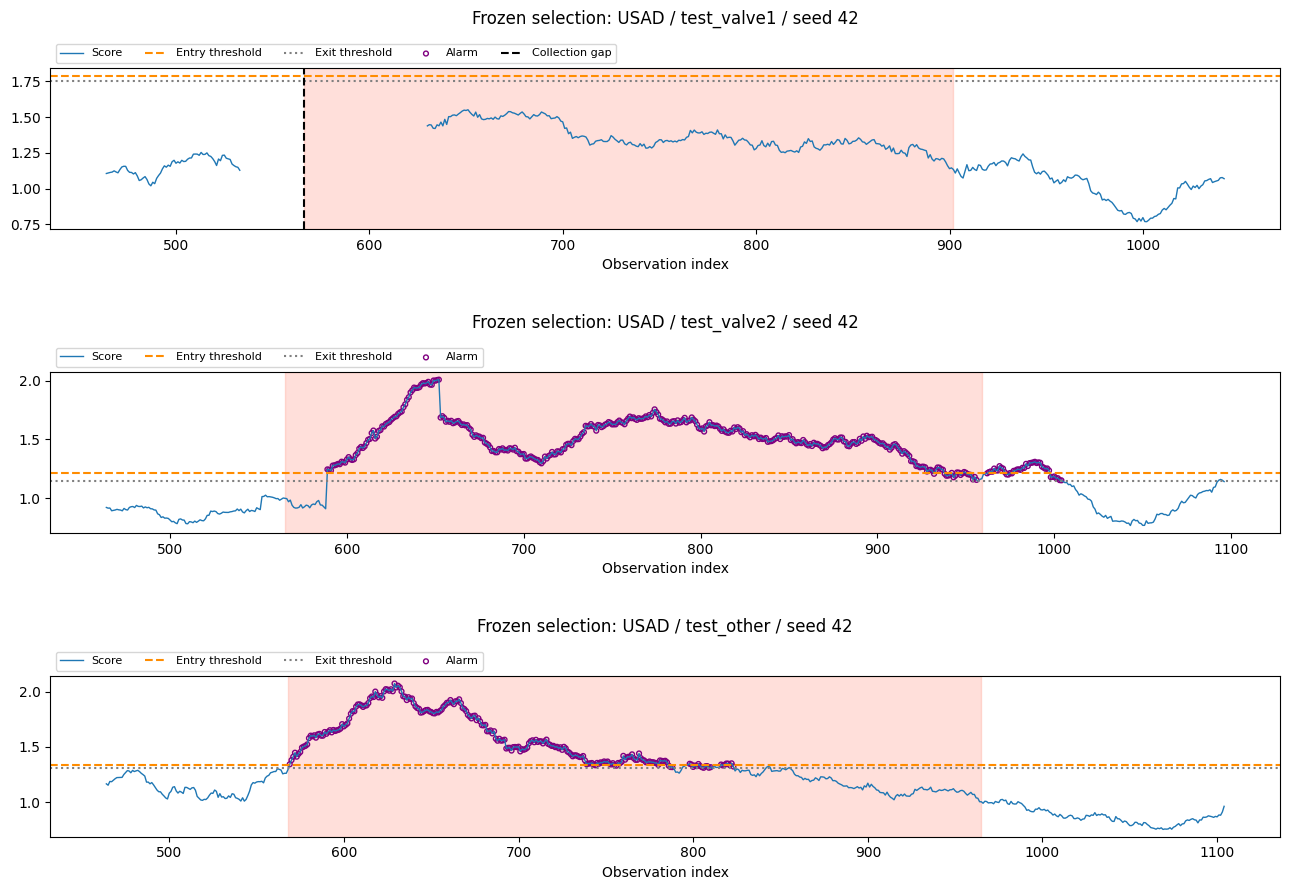

,method,file,TP,FP,FN,TN,unavailable_points
0,LSTMAD,test_valve1,3,0,334,338,192
1,LSTMAD,test_valve2,146,37,249,297,96
2,LSTMAD,test_other,81,23,317,316,96
3,USAD,test_valve1,0,0,337,338,192
4,USAD,test_valve2,368,43,27,291,96
5,USAD,test_other,241,0,157,339,96
6,PaAno,test_valve1,147,90,190,248,192
7,PaAno,test_valve2,391,154,4,180,96
8,PaAno,test_other,384,18,14,321,96


In [23]:
final_fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["F1", "FPR", "AUROC"]):
    means = test_results.groupby("method")[metric].mean().reindex(MODEL_REGISTRY)
    ax.bar(means.index, means.values)
    ax.set(title=f"Final macro {metric} (files and seeds)", ylim=(0, 1.05))
    ax.tick_params(axis="x", rotation=20)
final_fig.tight_layout()
plt.show()
chosen_method = frozen["selected"]["method"]
alarm_fig, axes = plt.subplots(3, 1, figsize=(13, 9))
for ax, (file_name, frame) in zip(axes, testing.items()):
    entry = final_entries[(chosen_method, file_name)]
    part, result = frame.iloc[CALIB_END:], entry["result"]
    ax.plot(part.index, result["score"], lw=1, label="Score")
    ax.axhline(result["high"], color="darkorange", ls="--", label="Entry threshold")
    if frozen["per_method"][chosen_method]["operation"]["trigger"] == "hysteresis":
        ax.axhline(result["low"], color="gray", ls=":", label="Exit threshold")
    ax.fill_between(part.index, 0, 1, where=part.anomaly.eq(1), transform=ax.get_xaxis_transform(), color="tomato", alpha=0.2)
    alarm = result["prediction"] == 1
    ax.scatter(part.index[alarm], result["score"][alarm], s=12, facecolors="none", edgecolors="purple", label="Alarm")
    gaps = frame.datetime.diff().dt.total_seconds().gt(GAP_SECONDS)
    for boundary in frame.index[gaps]:
        ax.axvline(boundary, color="black", ls="--", label="Collection gap")
    ax.set_title(f"Frozen selection: {chosen_method} / {file_name} / seed 42", pad=32)
    ax.set_xlabel("Observation index")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=5, fontsize=8)
alarm_fig.tight_layout(h_pad=3)
plt.show()

error_rows = []
for (method, file_name), entry in final_entries.items():
    frame = testing[file_name]
    y, pred = frame.anomaly.iloc[CALIB_END:].to_numpy(), entry["result"]["prediction"]
    error_rows.append({"method": method, "file": file_name, "TP": int(((y==1)&(pred==1)).sum()),
                       "FP": int(((y==0)&(pred==1)).sum()), "FN": int(((y==1)&(pred==0)).sum()),
                       "TN": int(((y==0)&(pred==0)).sum()),
                       "unavailable_points": int(np.isnan(entry["result"]["score"]).sum())})
display(pd.DataFrame(error_rows))

- 시험 파일 3개×시드 3개 평균 F1/AUROC는 LSTMAD **0.2472/0.5601**, USAD **0.5530/0.9610**, PaAno **0.6202/0.7753**임
- USAD는 점수 구분력이 높지만 valve1의 F1은 **0**임. valve2의 FPR은 **12.67%**로 파일별 요구를 넘음. 평균과 함께 각 파일의 점수·경보 위치를 확인할 필요가 있음
- 아래 파형과 오류 표는 시드 42의 예시임

### Step 20-1: 유량 변화와 세 모델의 경보 위치 비교

/tmp/ipykernel_3069140/3009732561.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  score_ax.boxplot([pa_score[(truth == label) & np.isfinite(pa_score)] for label in [0, 1]], labels=["Normal", "Anomaly"])
/tmp/ipykernel_3069140/3009732561.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  score_ax.boxplot([pa_score[(truth == label) & np.isfinite(pa_score)] for label in [0, 1]], labels=["Normal", "Anomaly"])
/tmp/ipykernel_3069140/3009732561.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  score_ax.boxplot([pa_score[(truth == label) & np.isfinite(pa_score)] for label in [0, 1]], labels=["Normal", "Anomaly"])


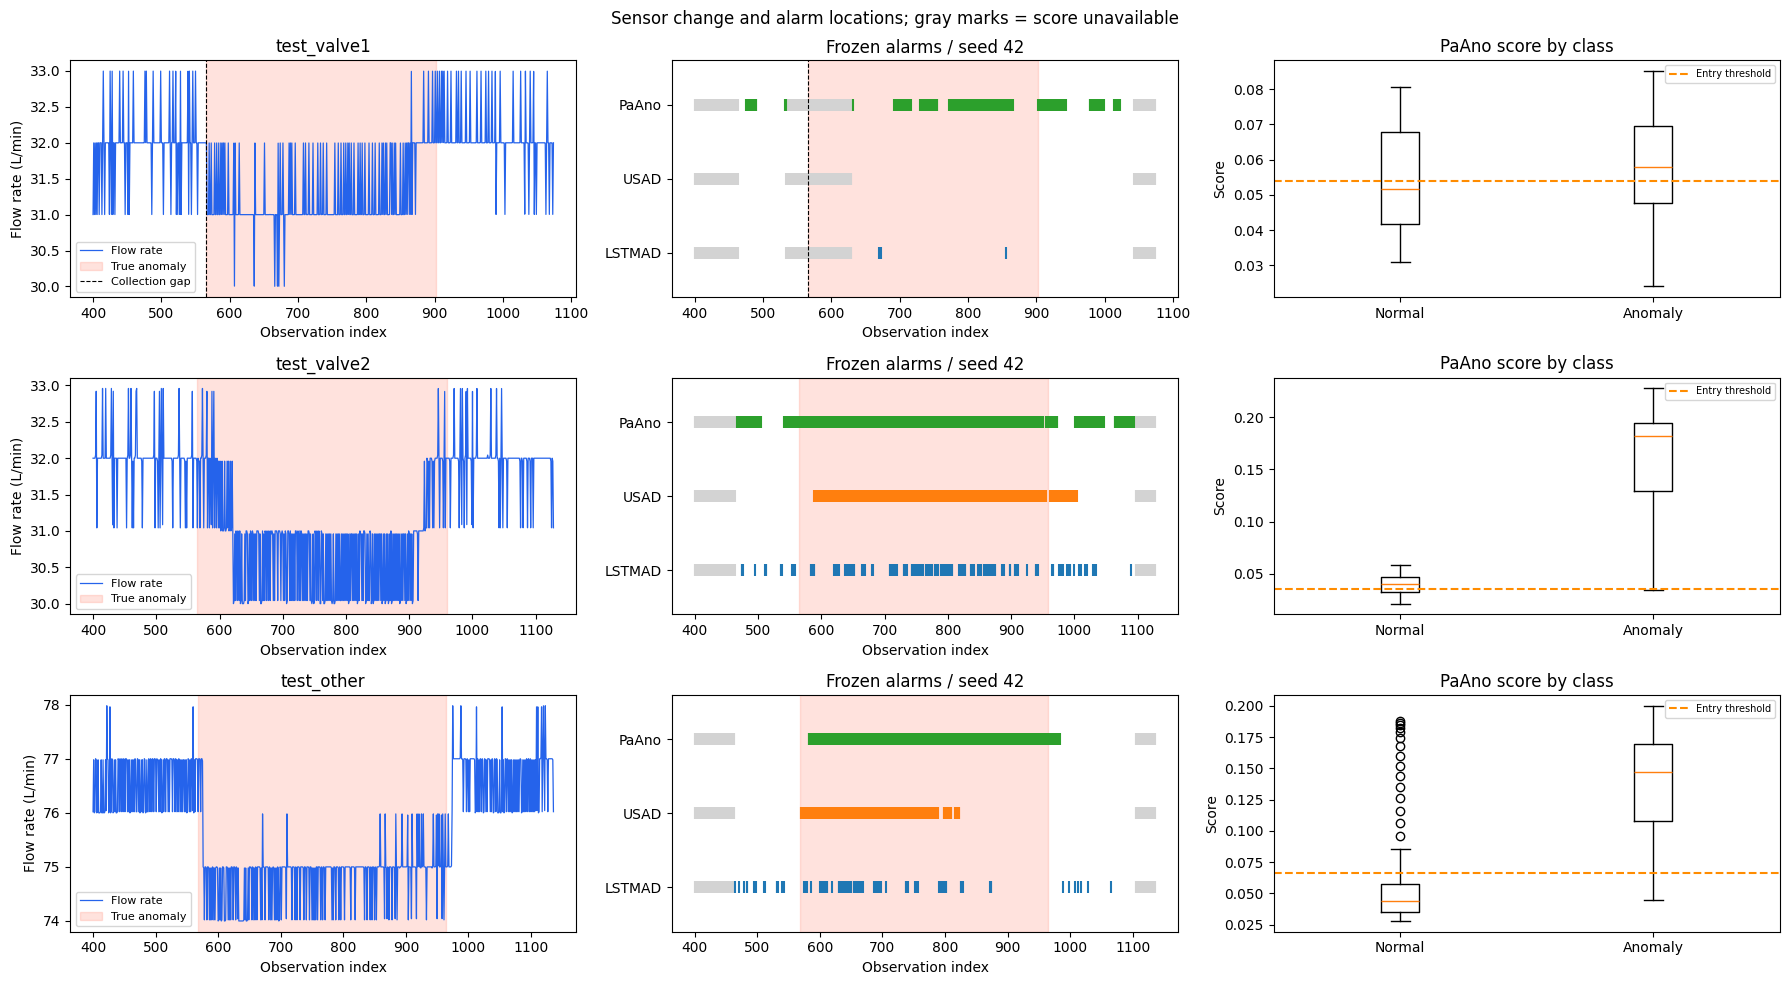

,file,role,n,flow_median
0,test_valve1,Normal,338,32.0000
1,test_valve1,Anomaly,337,31.0000
2,test_valve2,Normal,334,32.0000
3,test_valve2,Anomaly,395,30.9589
4,test_other,Normal,339,76.9796
5,test_other,Anomaly,398,75.0000


F1   AUROC     FPR  EventRecall  ScoredCoverage
method file                                                            
LSTMAD test_other   0.2957  0.4761  0.1082          1.0          0.8697
       test_valve1  0.0380  0.5643  0.0138          1.0          0.7156
       test_valve2  0.4079  0.6399  0.1068          1.0          0.8683
PaAno  test_other   0.9504  0.9619  0.0885          1.0          0.8697
       test_valve1  0.2183  0.4986  0.0888          1.0          0.7156
       test_valve2  0.8496  0.9125  0.1557          1.0          0.8683
USAD   test_other   0.7451  0.9325  0.0000          1.0          0.8697
       test_valve1  0.0000  0.9905  0.0000          0.0          0.7156
       test_valve2  0.9139  0.9600  0.1267          1.0          0.8683

In [24]:
sample_fig, sample_axes = plt.subplots(len(testing), 3, figsize=(18, 10), squeeze=False)
flow_rows = []
for row, (file_name, frame) in enumerate(testing.items()):
    part = frame.iloc[CALIB_END:]
    x, truth = part.index.to_numpy(), part.anomaly.to_numpy(dtype=int)
    flow_ax, alarm_ax, score_ax = sample_axes[row]
    flow_ax.plot(x, part.RateRMS, lw=0.9, color="#2563eb", label="Flow rate")
    for ax in [flow_ax, alarm_ax]:
        ax.fill_between(x, 0, 1, where=truth == 1, transform=ax.get_xaxis_transform(),
                        color="tomato", alpha=0.18, label="True anomaly")
        for gap in frame.index[frame.datetime.diff().dt.total_seconds().gt(GAP_SECONDS)]:
            ax.axvline(gap, color="black", ls="--", lw=0.8, label="Collection gap")
        ax.set_xlabel("Observation index")
    flow_ax.set(title=file_name, ylabel="Flow rate (L/min)")
    for level, method in enumerate(MODEL_REGISTRY):
        result = final_entries[(method, file_name)]["result"]
        fired, missing = result["prediction"] == 1, ~np.isfinite(result["score"])
        alarm_ax.scatter(x[missing], np.full(missing.sum(), level), marker="|", s=75, color="lightgray")
        alarm_ax.scatter(x[fired], np.full(fired.sum(), level), marker="|", s=75, color=f"C{level}")
    alarm_ax.set(yticks=range(3), yticklabels=list(MODEL_REGISTRY), ylim=(-0.6, 2.6),
                 title=f"Frozen alarms / seed {DEV_SEED}")
    pa_result = final_entries[("PaAno", file_name)]["result"]
    pa_score = pa_result["score"]
    score_ax.boxplot([pa_score[(truth == label) & np.isfinite(pa_score)] for label in [0, 1]], labels=["Normal", "Anomaly"])
    score_ax.axhline(pa_result["high"], color="darkorange", ls="--", label="Entry threshold")
    score_ax.set(title="PaAno score by class", ylabel="Score")
    score_ax.legend(fontsize=7)
    flow_ax.legend(fontsize=8, loc="best")
    for label, name in [(0, "Normal"), (1, "Anomaly")]:
        flow_rows.append({"file": file_name, "role": name, "n": int((truth == label).sum()),
                          "flow_median": part.loc[truth == label, "RateRMS"].median()})
sample_fig.suptitle("Sensor change and alarm locations; gray marks = score unavailable", fontsize=12)
sample_fig.tight_layout()
plt.show()
flow_summary = pd.DataFrame(flow_rows)
display(flow_summary.round(4))
display(test_results.groupby(["method", "file"])[["F1", "AUROC", "FPR", "EventRecall", "ScoredCoverage"]].mean().round(4))
flow_summary.to_csv(OUTPUT_DIR / "test_flow_summary.csv", index=False)
sample_fig.savefig(OUTPUT_DIR / "sensor_alarm_comparison.png", dpi=140, bbox_inches="tight")

- 왼쪽은 유량과 실제 이상 구간, 가운데는 모델별 경보 위치, 오른쪽은 PaAno의 정상·이상 점수 분포임. 회색 표시는 점수가 없는 위치임
- 정상→이상 유량 중앙값은 valve1 **32.00→31.00**, valve2 **32.00→30.96**, other **76.98→75.00**임. 낮아진 유량이 오래 이어지는 특징임
- PaAno의 valve1/valve2/other AUROC는 **0.4272/0.9365/0.9621**임. 오른쪽 상자에서 valve2·other는 이상 점수가 높지만 valve1은 두 분포가 겹치는 모습을 확인함
- valve1 시드 42의 PaAno 점수 중앙값은 정상 **0.0570**, 이상 **0.0532**임. 이 조건에서는 유량 변화가 있어도 정상 참조와의 특징 거리가 커지지 않은 결과임
- USAD valve1의 AUROC는 평균 **0.9905**이나 시험 점수 최댓값 **1.5508**이 시작 임계값 **1.7884**보다 낮아 F1이 0임
- valve1의 이상 시작 위치에는 **76초 수집 공백**이 있음. 공백 뒤 이상 64개가 점수 미가용이 되어 이상 337개 중 약 **19%**가 전체 행 F1에서 미탐으로 반영됨

### Step 20-2: 모델이 실제로 예측·복원한 값 확인

/tmp/ipykernel_3069140/3175947331.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  prediction_axes[1].boxplot(boxes, labels=box_labels, showmeans=True, showfliers=False)


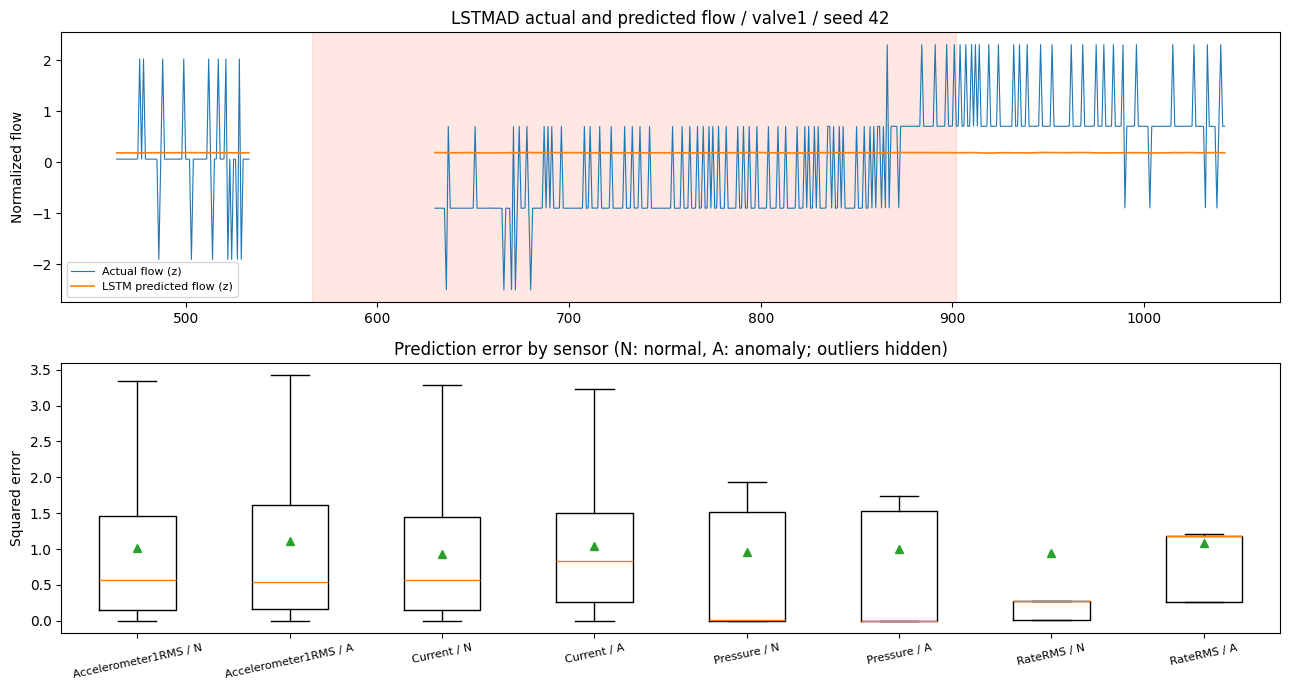

,sensor,normal_MSE,anomaly_MSE,error_AUROC
0,Accelerometer1RMS,1.01118,1.11789,0.50865
1,Current,0.93099,1.04733,0.55107
2,Pressure,0.95522,1.00190,0.46534
3,RateRMS,0.94189,1.08713,0.68878


Flow standard deviation: actual / predicted 1.0031600452129787 0.0024650828299525637


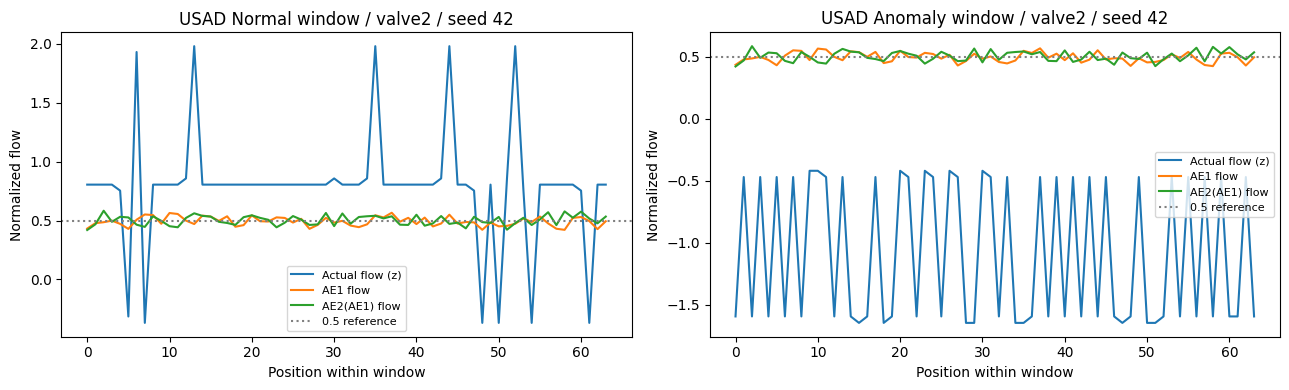

,role,actual_flow_mean,AE1_flow_mean,AE2AE1_flow_mean
0,Normal,0.78795,0.49250,0.50264
1,Anomaly,-1.08898,0.49266,0.50264


In [25]:
from torch.utils.data import DataLoader

# Existing fitted LSTMAD: inspect predictions without changing weights.
frame = testing["test_valve1"]
pipeline = final_entries[("LSTMAD", "test_valve1")]["pipeline"]
tail = frame.iloc[CALIB_END:]
actual = np.full((len(tail), len(pipeline.features)), np.nan)
predicted = actual.copy()
pipeline.model.model.eval()
for start, end in segment_bounds(tail):
    values = tail[pipeline.features].iloc[start:end].to_numpy(dtype=np.float32)
    if len(values) <= EDGE_LEFT + EDGE_RIGHT:
        continue
    dataset = ForecastDataset(values, window_size=pipeline.window, pred_len=1)
    batches = []
    with torch.no_grad():
        for inputs, _ in DataLoader(dataset, batch_size=64, shuffle=False):
            batches.append(pipeline.model.model(inputs.to(pipeline.model.device)).squeeze(0).cpu().numpy())
    predicted[start + pipeline.window:end] = np.concatenate(batches)
    actual[start + pipeline.window:end] = dataset.targets[:, 0, :].numpy()
native = final_entries[("LSTMAD", "test_valve1")]["raw"][CALIB_END:]
mask = np.isfinite(native)
errors = (actual - predicted) ** 2
np.testing.assert_allclose(errors[mask].mean(axis=1), native[mask], rtol=1e-5, atol=1e-6)
flow_column = pipeline.features.index("RateRMS")
truth = tail.anomaly.to_numpy()
prediction_fig, prediction_axes = plt.subplots(2, 1, figsize=(13, 7))
prediction_axes[0].plot(tail.index, np.where(mask, actual[:, flow_column], np.nan), lw=0.8, label="Actual flow (z)")
prediction_axes[0].plot(tail.index, np.where(mask, predicted[:, flow_column], np.nan), lw=1.2, label="LSTM predicted flow (z)")
prediction_axes[0].fill_between(tail.index, 0, 1, where=truth == 1, transform=prediction_axes[0].get_xaxis_transform(), color="tomato", alpha=0.15)
prediction_axes[0].set(title="LSTMAD actual and predicted flow / valve1 / seed 42", ylabel="Normalized flow")
prediction_axes[0].legend(fontsize=8)
error_rows, boxes, box_labels = [], [], []
for column, feature in enumerate(pipeline.features):
    for label, name in [(0, "N"), (1, "A")]:
        boxes.append(errors[mask & (truth == label), column])
        box_labels.append(feature + " / " + name)
    error_rows.append({"sensor": feature, "normal_MSE": errors[mask & (truth == 0), column].mean(),
                       "anomaly_MSE": errors[mask & (truth == 1), column].mean(),
                       "error_AUROC": roc_auc_score(truth[mask], errors[mask, column])})
prediction_axes[1].boxplot(boxes, labels=box_labels, showmeans=True, showfliers=False)
prediction_axes[1].tick_params(axis="x", rotation=12, labelsize=8)
prediction_axes[1].set(ylabel="Squared error", title="Prediction error by sensor (N: normal, A: anomaly; outliers hidden)")
prediction_fig.tight_layout()
plt.show()
lstm_error_summary = pd.DataFrame(error_rows)
display(lstm_error_summary.round(5))
print("Flow standard deviation: actual / predicted", np.std(actual[mask, flow_column]), np.std(predicted[mask, flow_column]))
lstm_error_summary.to_csv(OUTPUT_DIR / "lstm_sensor_errors.csv", index=False)
prediction_fig.savefig(OUTPUT_DIR / "lstm_prediction_errors.png", dpi=140, bbox_inches="tight")

# Existing fitted USAD: inspect one normal and one anomalous window.
frame = testing["test_valve2"]
pipeline = final_entries[("USAD", "test_valve2")]["pipeline"]
part = frame.iloc[CALIB_END:]
dataset = ReconstructDataset(part[pipeline.features].to_numpy(dtype=np.float32), window_size=pipeline.window)
flow_column = pipeline.features.index("RateRMS")
reconstruction_fig, reconstruction_axes = plt.subplots(1, 2, figsize=(13, 4))
reconstruction_rows = []
pipeline.model.model.eval()
for ax, label, name in zip(reconstruction_axes, [0, 1], ["Normal", "Anomaly"]):
    starts = [i for i in range(EDGE_LEFT, len(dataset))
              if part.anomaly.iloc[i:i + pipeline.window].eq(label).all()]
    start = starts[len(starts) // 2]
    target = dataset.samples[start:start + 1]
    with torch.no_grad():
        ae1, _, ae2ae1 = pipeline.model.model(target.to(pipeline.model.device))
    first = ae1.cpu().numpy().reshape(pipeline.window, -1)
    chained = ae2ae1.cpu().numpy().reshape(pipeline.window, -1)
    ax.plot(target.numpy()[0, :, flow_column], label="Actual flow (z)")
    ax.plot(first[:, flow_column], label="AE1 flow")
    ax.plot(chained[:, flow_column], label="AE2(AE1) flow")
    ax.axhline(0.5, color="gray", ls=":", label="0.5 reference")
    ax.set(title=f"USAD {name} window / valve2 / seed 42", xlabel="Position within window", ylabel="Normalized flow")
    ax.legend(fontsize=8)
    reconstruction_rows.append({"role": name, "actual_flow_mean": target.numpy()[0, :, flow_column].mean(),
                                 "AE1_flow_mean": first[:, flow_column].mean(), "AE2AE1_flow_mean": chained[:, flow_column].mean()})
reconstruction_fig.tight_layout()
plt.show()
display(pd.DataFrame(reconstruction_rows).round(5))
reconstruction_fig.savefig(OUTPUT_DIR / "usad_reconstruction_examples.png", dpi=140, bbox_inches="tight")

- 실제·예측·복원 곡선의 세로축은 원래 유량 단위가 아닌 **표준화된 값(z-score)**임
- 첫 그림에서 실제 유량은 변하지만 LSTMAD의 예측선은 거의 일정한 모습을 확인함. 현재 설정에서는 평균 근처의 예측과 비슷한 동작이 나타남
- 아래 상자그림은 센서별 예측오차임. N은 정상, A는 이상이며 삼각형은 평균임. 큰 바깥 점은 생략하여 가운데 분포를 보기 쉽게 표시함
- LSTMAD는 네 센서 오차를 같은 비중으로 평균함. 유량에서 얻은 구분 정보가 다른 센서 오차와 섞이는 정도를 표의 센서별 AUROC로 확인함
- USAD 그림은 같은 학습 모델의 정상·이상 윈도 예시임. Sigmoid 복원 출력은 0~1 범위이며, 복원선이 0.5 부근에 모이는 반면 실제 이상 유량은 낮아져 복원값과의 거리가 커지는 모습을 확인함
- 이번 USAD에서는 유량이 낮아질 때 실제 값과 0.5 부근 복원값의 거리가 커짐. 복원 출력이 실제 신호를 얼마나 반영하는지 살펴볼 필요가 있음을 보여주는 예시임

### Step 21: 실험 설정과 결과 저장

In [26]:
native_checks = []
expected_classes = {"LSTMAD":LSTMAD,"USAD":USAD,"PaAno":PaAno_PAI}
for method in MODEL_REGISTRY:
    entry = final_entries[(method,"test_valve1")]
    pipeline = entry["pipeline"]
    assert type(pipeline.model) is expected_classes[method]
    assert np.isfinite(pipeline.prefix_scores[VALID_END:CALIB_END]).sum() == 48
    assert np.array_equal(np.isfinite(entry["raw"]),common_ranking_mask(testing["test_valve1"]))
    native_checks.append({"method":method,"native_class":type(pipeline.model).__module__+"."+type(pipeline.model).__name__,
                          "normal_calibration_points":48})
provenance = {name:{"file":frame.attrs["relative_path"],"sha256":frame.attrs["sha256"],
                    "source_commit":frame.attrs["source_commit"]} for name,frame in {**development,**testing}.items()}
run_manifest = {"notebook":"03_tsb_ad_advanced.ipynb","source_commits":frozen["source_commits"],"data":provenance,
    "development_fits":len(fit_log),"development_configs":len(comparison),"development_file_trials":len(trials),
    "final_runs":len(test_results),"frozen_design_sha256":frozen_hash,"native_model_checks":native_checks,
    "selection_uses_final_test":False,"normal_prefix_adaptation_per_file":True,
    "evaluation_scope":"offline native API; per-array normalization and native point aggregation",
    "common_edges":[EDGE_LEFT,EDGE_RIGHT],"normal_calibration_points":48,
    "device":str(DEVICE),"device_name":torch.cuda.get_device_name(DEVICE) if DEVICE.type=="cuda" else "cpu",
    "torch":torch.__version__,"cuda":torch.version.cuda}
(OUTPUT_DIR/"run_manifest.json").write_text(json.dumps(run_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
for figure,filename in [(raw_fig,"raw_sensors"),(eda_fig,"eda"),(input_fig,"input_samples"),
                       (ablation_fig,"input_ablation"),(operation_fig,"operation_sensitivity"),
                       (method_fig,"methods"),(validation_fig,"normal_calibration"),
                       (final_fig,"final_metrics"),(alarm_fig,"final_alarms")]:
    figure.savefig(OUTPUT_DIR/f"{filename}.png",dpi=140,bbox_inches="tight")
print("Saved:",OUTPUT_DIR)
display(pd.DataFrame(native_checks))

Saved: /home/chohi/PythonProjectLLM/AI_EDU/13w/results/03_tsb_ad_advanced


,method,native_class,normal_calibration_points
0,LSTMAD,TSB_AD.models.LSTMAD.LSTMAD,48
1,USAD,TSB_AD.models.USAD.USAD,48
2,PaAno,TSB_AD.models.PaAno_PAI.PaAno_PAI,48


- 선정 설정, 데이터 출처와 실행 결과를 `OUTPUT_DIR`에 저장하여 실험 조건과 성능을 함께 확인함

### Step 22: 히스토그램으로 임계값 조정 효과 확인

- 시험 정답으로 임계값을 조정하여 탐지와 오경보가 어떻게 바뀌는지 살펴보는 **사후 분석**임
- 앞서 보고한 시험 성능과 구분하여, 같은 모델 점수에서 경보 기준의 영향을 확인함

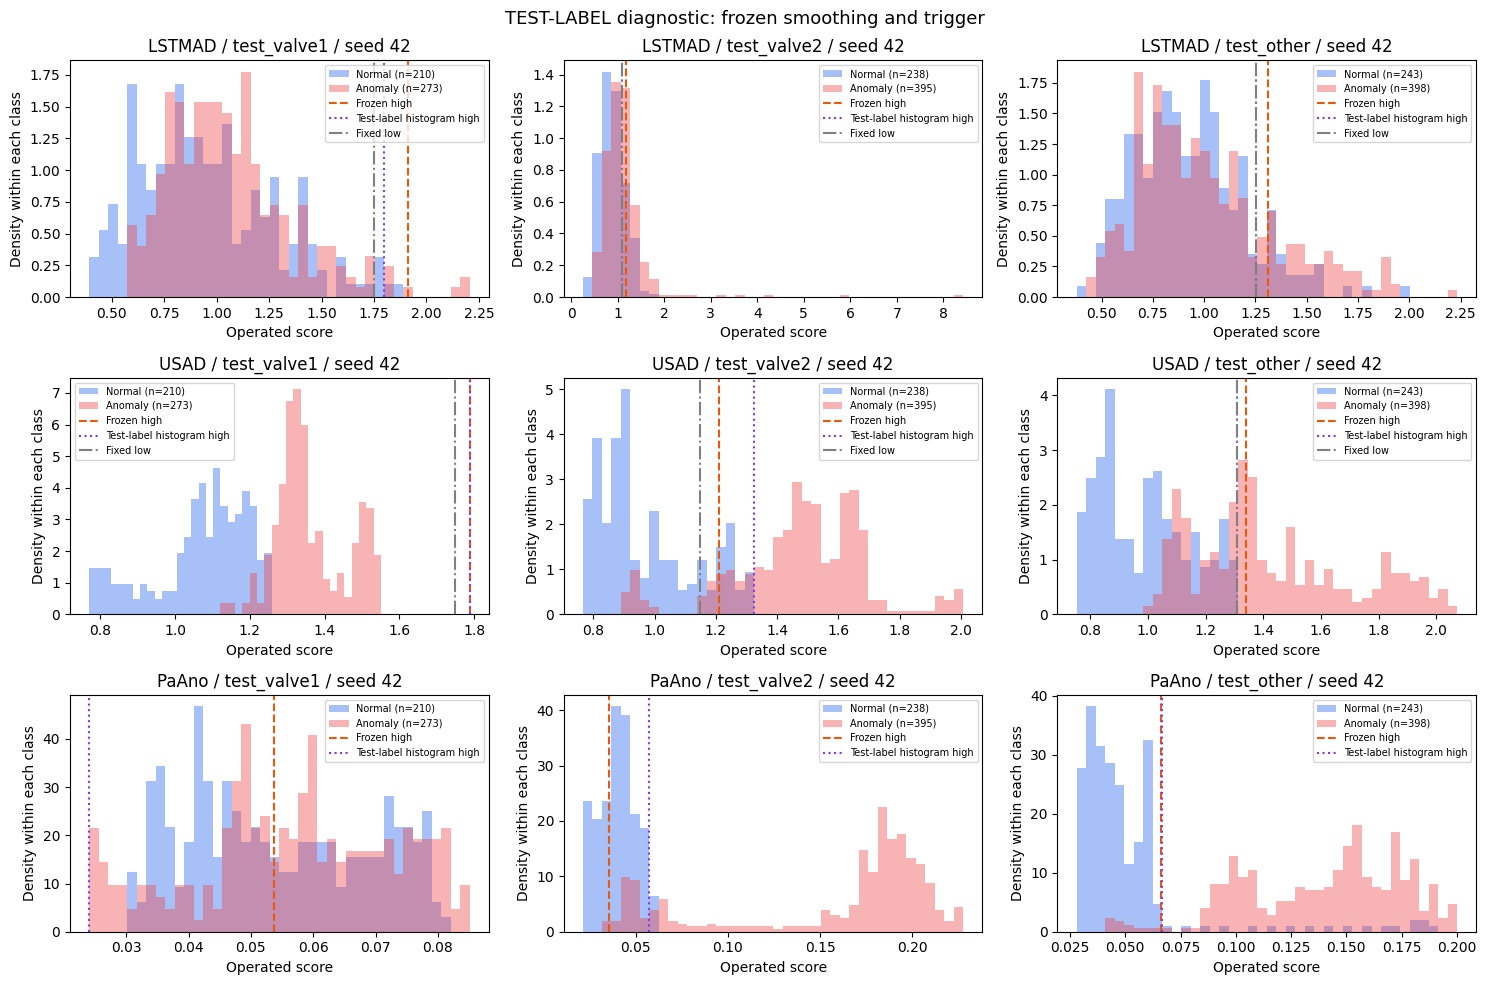

,method,file,seed,scope,high,F1,FPR,diagnostic_available
0,LSTMAD,test_valve1,42,Frozen,1.9117,0.0176,0.0000,True
1,LSTMAD,test_valve1,42,Histogram oracle,1.7979,0.0405,0.0059,True
2,LSTMAD,test_valve1,52,Frozen,1.7230,0.0621,0.0178,True
3,LSTMAD,test_valve1,52,Histogram oracle,1.6983,0.0730,0.0178,True
4,LSTMAD,test_valve1,62,Frozen,1.7616,0.0342,0.0237,True
5,LSTMAD,test_valve1,62,Histogram oracle,1.6836,0.0563,0.0237,True
6,LSTMAD,test_valve2,42,Frozen,1.1801,0.5052,0.1108,True
7,LSTMAD,test_valve2,42,Histogram oracle,1.0839,0.5737,0.1497,True
8,LSTMAD,test_valve2,52,Frozen,1.2301,0.4060,0.0988,True
9,LSTMAD,test_valve2,52,Histogram oracle,1.1502,0.4504,0.1257,True


In [27]:
hist_f1_score = binary_f1_score  # fast binary F1 from cell 34 (same values as sklearn f1_score)

assert hashlib.sha256((OUTPUT_DIR / "frozen_design.json").read_bytes()).hexdigest() == frozen_hash
hist_rows, hist_entries = [], {}
hist_methods, hist_files = list(frozen["per_method"]), list(testing)
hist_distribution_fig, hist_axes = plt.subplots(len(hist_methods), len(hist_files), figsize=(15, 10), squeeze=False)
for (hist_method, hist_file, hist_seed), hist_entry in test_scored.items():
    hist_frame, hist_original = testing[hist_file], hist_entry["result"]
    hist_y = hist_frame.iloc[CALIB_END:].anomaly.to_numpy(dtype=int)
    hist_score = np.asarray(hist_original["score"], dtype=float)
    hist_finite = np.isfinite(hist_score)
    hist_trigger = frozen["per_method"][hist_method]["operation"]["trigger"]
    hist_high, hist_low = float(hist_original["high"]), float(hist_original["low"])
    hist_candidates, hist_candidate_f1 = np.array([hist_high]), np.array([hist_f1_score(hist_y, hist_original["prediction"], zero_division=0)])
    hist_ready = hist_finite.any() and np.unique(hist_y).size == 2
    hist_bins = None
    if hist_ready:
        hist_bins = np.histogram_bin_edges(hist_score[hist_finite], bins=40)
        hist_candidates = np.unique(np.r_[np.nextafter(hist_bins[0], -np.inf), hist_bins, hist_high])
        if hist_trigger == "hysteresis":
            hist_candidates = np.unique(np.r_[hist_candidates[hist_candidates >= hist_low], hist_low])
        hist_candidate_f1 = np.array([hist_f1_score(hist_y, alarm_from_scores(hist_score, hist_tau, hist_low, hist_trigger), zero_division=0) for hist_tau in hist_candidates])
        hist_high = float(hist_candidates[np.flatnonzero(hist_candidate_f1 == hist_candidate_f1.max())[-1]])
    hist_prediction = alarm_from_scores(hist_score, hist_high, hist_low, hist_trigger) if hist_ready else hist_original["prediction"].copy()
    hist_result = {**hist_original, "prediction": hist_prediction, "high": hist_high}
    hist_entries[(hist_method, hist_file, hist_seed)] = {"result": hist_result, "candidates": hist_candidates, "candidate_F1": hist_candidate_f1, "diagnostic_available": bool(hist_ready)}
    hist_before = test_results.loc[test_results.method.eq(hist_method) & test_results.file.eq(hist_file) & test_results.seed.eq(hist_seed)].iloc[0].to_dict()
    hist_rows.append({**hist_before, "scope": "Frozen", "diagnostic_available": bool(hist_ready)})
    hist_rows.append({**hist_before, **run_metrics(hist_frame, hist_result), "high": hist_high, "scope": "Histogram oracle", "diagnostic_available": bool(hist_ready)})
    if hist_seed == DEV_SEED:
        hist_ax = hist_axes[hist_methods.index(hist_method), hist_files.index(hist_file)]
        if hist_bins is not None:
            for hist_label, hist_color, hist_label_name in [(0, "#2563eb", "Normal"), (1, "#ef4444", "Anomaly")]:
                hist_mask = hist_finite & (hist_y == hist_label)
                if hist_mask.any():
                    hist_ax.hist(hist_score[hist_mask], bins=hist_bins, density=True, alpha=0.4, color=hist_color, label=f"{hist_label_name} (n={hist_mask.sum()})")
        hist_ax.axvline(hist_original["high"], color="#ea580c", ls="--", label="Frozen high")
        hist_ax.axvline(hist_high, color="#7c3aed", ls=":", label="Test-label histogram high")
        if hist_trigger == "hysteresis":
            hist_ax.axvline(hist_low, color="gray", ls="-.", label="Fixed low")
        hist_ax.set(title=f"{hist_method} / {hist_file} / seed {hist_seed}", xlabel="Operated score", ylabel="Density within each class")
        hist_ax.legend(fontsize=7)
hist_comparison = pd.DataFrame(hist_rows)
hist_distribution_fig.suptitle("TEST-LABEL diagnostic: frozen smoothing and trigger", fontsize=13)
hist_distribution_fig.tight_layout()
plt.show()
display(hist_comparison[["method", "file", "seed", "scope", "high", "F1", "FPR", "diagnostic_available"]].round(4))

- 가로축은 점수, 파란색은 정상, 빨간색은 이상 분포임. 각 집단의 면적을 1로 맞춘 밀도이며 범례의 n이 관측 개수임
- 이상 분포가 정상보다 오른쪽에 떨어져 있으면 구분하기 쉽고, 많이 겹치면 탐지를 늘릴 때 오경보도 늘어날 수 있음
- 주황 선은 기존 시작 임계값, 보라 선은 사후 임계값, 회색 선은 고정 종료 임계값임. 40개 구간의 경계와 기존 임계값 중 F1이 가장 높은 후보를 선택함
- EMA·3연속·히스테리시스 규칙은 유지하며 히스테리시스는 시작 임계값이 종료 임계값 이상인 후보를 비교함

### Step 23: 동결 성능과 사후 진단의 경보 위치 비교

Accuracy              F1             FPR  \
                                        mean     std    mean     std    mean   
method file        scope                                                       
LSTMAD test_other  Frozen             0.5124  0.0258  0.2957  0.0277  0.1082   
                   Histogram oracle   0.5124  0.0252  0.3196  0.0211  0.1347   
       test_valve1 Frozen             0.5037  0.0053  0.0380  0.0225  0.0138   
                   Histogram oracle   0.5077  0.0037  0.0566  0.0163  0.0158   
       test_valve2 Frozen             0.5624  0.0453  0.4079  0.0964  0.1068   
                   Histogram oracle   0.5761  0.0583  0.4501  0.1237  0.1327   
PaAno  test_other  Frozen             0.9448  0.0228  0.9504  0.0194  0.0885   
                   Histogram oracle   0.9579  0.0062  0.9613  0.0058  0.0541   
       test_valve1 Frozen             0.5412  0.0384  0.2183  0.2553  0.0888   
                   Histogram oracle   0.5941  0.0000  0.6642  0.0000  0.6154   
       test_valve2 Frozen             0.8390  0.0635  0.8496  0.0512  0.1557   
                   Histogram oracle   0.8985  0.0357  0.8974  0.0387  0.0140   
USAD   test_other  Frozen             0.7806  0.0055  0.7451  0.0080  0.0000   
                   Histogram oracle   0.7992  0.0059  0.7718  0.0085  0.0010   
       test_valve1 Frozen             0.5007  0.0000  0.0000  0.0000  0.0000   
                   Histogram oracle   0.5007  0.0000  0.0000  0.0000  0.0000   
       test_valve2 Frozen             0.9049  0.0029  0.9139  0.0024  0.1267   
                   Histogram oracle   0.9479  0.0000  0.9495  0.0000  0.0000   

                                              AUROC         EventRecall       \
                                        std    mean     std        mean  std   
method file        scope                                                       
LSTMAD test_other  Frozen            0.0385  0.4761  0.0791         1.0  0.0   
                   Histogram oracle  0.0485  0.4761  0.0791         1.0  0.0   
       test_valve1 Frozen            0.0123  0.5643  0.0469         1.0  0.0   
                   Histogram oracle  0.0090  0.5643  0.0469         1.0  0.0   
       test_valve2 Frozen            0.0069  0.6399  0.0545         1.0  0.0   
                   Histogram oracle  0.0148  0.6399  0.0545         1.0  0.0   
PaAno  test_other  Frozen            0.0491  0.9619  0.0261         1.0  0.0   
                   Histogram oracle  0.0045  0.9619  0.0261         1.0  0.0   
       test_valve1 Frozen            0.1537  0.4986  0.2055         1.0  0.0   
                   Histogram oracle  0.0000  0.4986  0.2055         1.0  0.0   
       test_valve2 Frozen            0.2645  0.9125  0.0535         1.0  0.0   
                   Histogram oracle  0.0151  0.9125  0.0535         1.0  0.0   
USAD   test_other  Frozen            0.0000  0.9325  0.0007         1.0  0.0   
                   Histogram oracle  0.0017  0.9325  0.0007         1.0  0.0   
       test_valve1 Frozen            0.0000  0.9905  0.0001         0.0  0.0   
                   Histogram oracle  0.0000  0.9905  0.0001         0.0  0.0   
       test_valve2 Frozen            0.0062  0.9600  0.0005         1.0  0.0   
                   Histogram oracle  0.0000  0.9600  0.0005         1.0  0.0   

                                    MeanDelayObs           MeanDelaySeconds  \
                                            mean       std             mean   
method file        scope                                                      
LSTMAD test_other  Frozen                 7.0000    0.0000           7.0000   
                   Histogram oracle       6.6667    0.5774           6.6667   
       test_valve1 Frozen                97.3333   11.5470         103.0000   
                   Histogram oracle      84.0000    0.0000          89.0000   
       test_valve2 Frozen                18.0000    0.0000          19.0000   
                   Histogram oracle      1

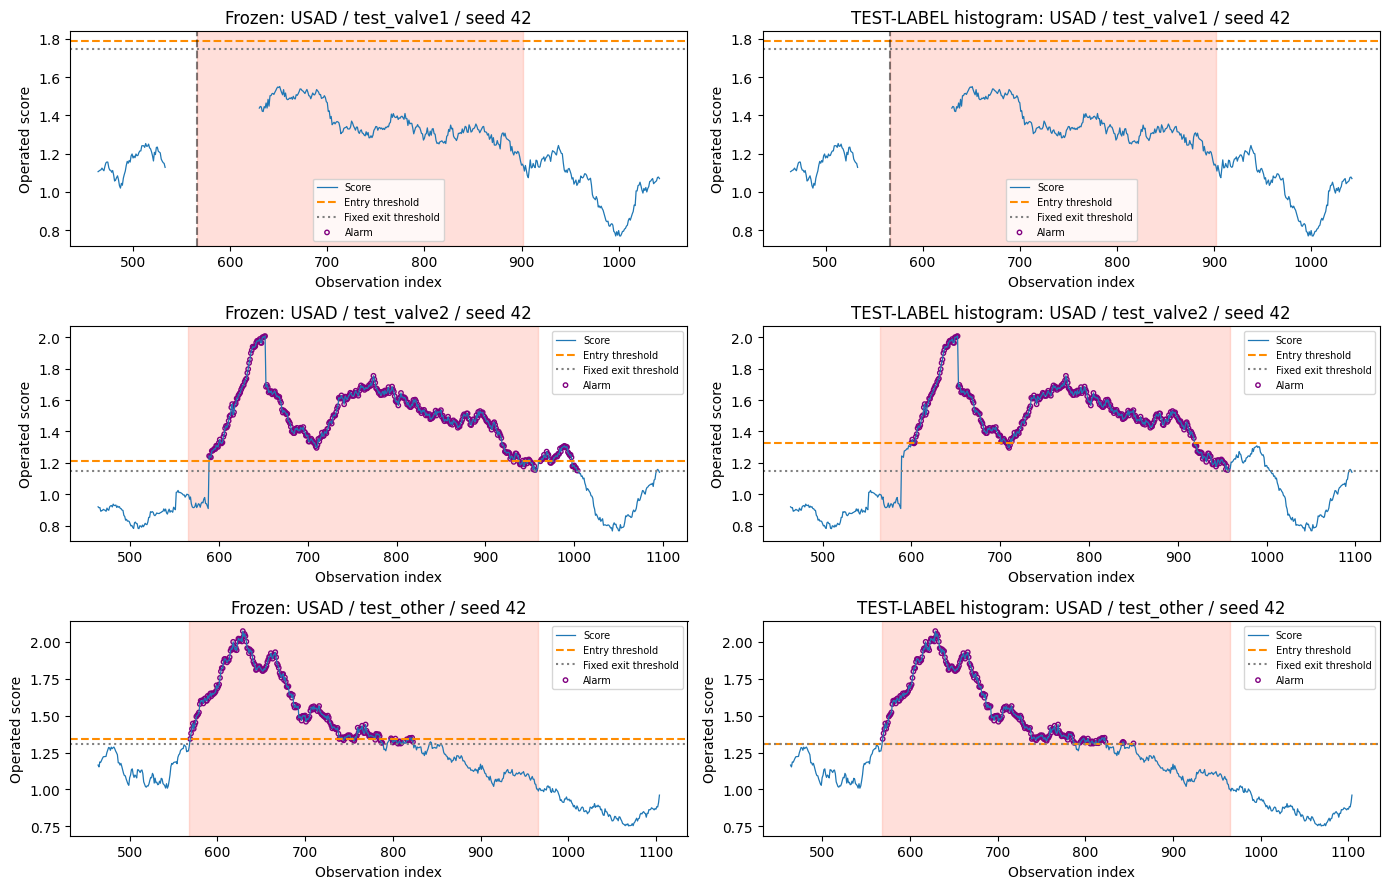

Saved TEST-LABEL diagnostics: /home/chohi/PythonProjectLLM/AI_EDU/13w/results/03_tsb_ad_advanced/histogram_diagnostic


In [28]:
hist_metrics = ["Accuracy", "F1", "FPR", "AUROC", "EventRecall", "MeanDelayObs", "MeanDelaySeconds"]
hist_summary = hist_comparison.groupby(["method", "file", "scope"])[hist_metrics].agg(["mean", "std"])
display(hist_summary.round(4))
hist_selected = frozen["selected"]["method"]
hist_alarm_fig, hist_alarm_axes = plt.subplots(len(hist_files), 2, figsize=(14, 9), squeeze=False)
for hist_row, hist_file in enumerate(hist_files):
    hist_part = testing[hist_file].iloc[CALIB_END:]
    hist_original = test_scored[(hist_selected, hist_file, DEV_SEED)]["result"]
    hist_after = hist_entries[(hist_selected, hist_file, DEV_SEED)]["result"]
    for hist_ax, hist_scope, hist_result in zip(hist_alarm_axes[hist_row], ["Frozen", "TEST-LABEL histogram"], [hist_original, hist_after]):
        hist_ax.plot(hist_part.index, hist_result["score"], lw=0.9, label="Score")
        hist_ax.axhline(hist_result["high"], color="darkorange", ls="--", label="Entry threshold")
        if frozen["per_method"][hist_selected]["operation"]["trigger"] == "hysteresis":
            hist_ax.axhline(hist_result["low"], color="gray", ls=":", label="Fixed exit threshold")
        hist_ax.fill_between(hist_part.index, 0, 1, where=hist_part.anomaly.eq(1), transform=hist_ax.get_xaxis_transform(), color="tomato", alpha=0.2)
        hist_alarm = hist_result["prediction"] == 1
        hist_ax.scatter(hist_part.index[hist_alarm], hist_result["score"][hist_alarm], s=10, facecolors="none", edgecolors="purple", label="Alarm")
        for hist_gap in testing[hist_file].index[testing[hist_file].datetime.diff().dt.total_seconds().gt(GAP_SECONDS)]:
            if hist_gap >= CALIB_END:
                hist_ax.axvline(hist_gap, color="black", ls="--", alpha=0.5)
        hist_ax.set(title=f"{hist_scope}: {hist_selected} / {hist_file} / seed {DEV_SEED}", xlabel="Observation index", ylabel="Operated score")
        hist_ax.legend(fontsize=7)
hist_alarm_fig.tight_layout()
plt.show()
hist_directory = OUTPUT_DIR / "histogram_diagnostic"
hist_directory.mkdir(parents=True, exist_ok=True)
hist_comparison.to_csv(hist_directory / "comparison.csv", index=False)
hist_summary.to_csv(hist_directory / "summary.csv")
pd.DataFrame([{"method": hist_key[0], "file": hist_key[1], "seed": hist_key[2], "high": hist_tau, "F1": hist_f1} for hist_key, hist_value in hist_entries.items() for hist_tau, hist_f1 in zip(hist_value["candidates"], hist_value["candidate_F1"])]).to_csv(hist_directory / "candidate_grid.csv", index=False)
pd.concat([pd.DataFrame({"method": hist_key[0], "file": hist_key[1], "seed": hist_key[2], "observation": testing[hist_key[1]].iloc[CALIB_END:].index, "prediction": hist_value["result"]["prediction"]}) for hist_key, hist_value in hist_entries.items()], ignore_index=True).to_csv(hist_directory / "diagnostic_predictions.csv", index=False)
hist_distribution_fig.savefig(hist_directory / "threshold_histograms.png", dpi=150, bbox_inches="tight")
hist_alarm_fig.savefig(hist_directory / "selected_alarm_comparison.png", dpi=150, bbox_inches="tight")
assert hashlib.sha256((OUTPUT_DIR / "frozen_design.json").read_bytes()).hexdigest() == frozen_hash
print("Saved TEST-LABEL diagnostics:", hist_directory)

- 표는 파일·방법·시드마다 사후 임계값을 고른 뒤 평균한 값이며, 경보 그림은 USAD의 시드 42 예시임
- PaAno의 평균 F1은 **0.6202→0.8472**이나 FPR도 **7.05%→22.78%**로 높아짐. valve1 시드 42에서는 정상 338개 중 **208개에 경보하여 FPR이 61.54%**임
- 시드 42의 valve2·other는 반대로 임계값을 높여 오경보를 줄이는 방향임. 파일별로 필요한 조정 방향이 다름을 확인함
- USAD valve1은 시험 점수 최댓값 **1.5508**이 고정 종료 임계값 **1.7487**보다 낮아, 시작 임계값만 바꾸는 이번 범위에서는 경보가 계속 0임
- 같은 점수에서 경보만 바꾸므로 AUROC는 그대로임. 탐지 증가와 오경보 증가를 함께 확인하여 임계값 조정의 효과를 해석함

## 9) 결론

- 개발 요구를 만족한 **USAD·W64·핵심 4개 센서·95% 분위수·원점수·히스테리시스**를 선정함
- 개발 평균 F1 **0.5759**·FPR **0%**, 최종 평균 F1 **0.5530**·FPR **4.22%**임. 최종 valve1의 미탐과 valve2의 오경보 초과가 남아 조건별 개선이 필요함
- 센서 추가 비교, 원본 센서·윈도별 점수와 경보 비교, 실제 예측·복원값과 경보 확대 그림을 통해 성능 수치가 달라진 이유를 확인함

**한계점과 개선 방향**

- 개발 파일 2개와 보정 유효 점수 48개를 사용한 결과임. 정상 운전 모드와 독립 실험 파일을 늘려 설계의 안정성을 확인할 필요가 있음
- 현재 구현과 학습 횟수에서 얻은 비교임. 정상 자료와 학습 예산을 늘려 예측·복원 결과와 탐지 성능이 개선되는지 확인할 필요가 있음
- 점수 계산에는 이후 관측이 사용될 수 있음. 실제 운영 시스템에서는 도착한 자료만으로 전처리·점수 계산을 수행하고 경보 시점을 다시 검증할 필요가 있음
- 사후 임계값 분석은 개선 방향을 찾는 자료임. 운영에 적용할 임계값은 별도 개발 자료에서 정하고 새로운 시험 자료로 성능을 확인할 필요가 있음

**확인 질문**

- 센서를 하나 추가했을 때 점수 구분력과 오경보는 어떻게 바뀌었는가?
- W16·W64에서 같은 센서 변화에 대한 점수와 경보는 어떻게 달라지는가?
- 3연속·EMA·히스테리시스는 경보 진입과 해제 위치를 어떻게 바꾸었는가?
- AUROC가 높아도 경보가 없을 수 있는 이유는 무엇인가?

**출처**

- [SKAB 데이터 설명](https://github.com/waico/SKAB/blob/b2c0d46c2971dcbfe71e26087b6d231998bb91c2/README.md) · [정상 준비 프로토콜](https://github.com/waico/SKAB/issues/9)
- [LSTMAD](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/models/LSTMAD.py) · [USAD](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/models/USAD.py) · [PaAno_PAI](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/TSB_AD/models/PaAno_PAI.py)
- [TSB-AD Apache-2.0](https://github.com/TheDatumOrg/TSB-AD/blob/303dffbfc11612995b17b06633f8c9d0ea0e38e5/LICENSE) · [SKAB GPL-3.0](https://github.com/waico/SKAB/blob/b2c0d46c2971dcbfe71e26087b6d231998bb91c2/LICENSE)